# Deteksi Kanker Kolorektal dari Sekuens 16S rRNA Mikrobioma Feses dengan Machine Learning

**Judul:** Deteksi Kanker Kolorektal Berdasarkan Data Sekuens 16S rRNA (FASTQ) Mikrobioma Feses
Menggunakan Logistic Regression dan Random Forest.

**Kesesuaian tema tugas** (*Pengembangan Model Machine Learning untuk Deteksi Penyakit Berdasarkan
Data Sekuens DNA/RNA*): input utama adalah **berkas FASTQ mentah** hasil sekuensing DNA gen 16S rRNA
(region V4, Illumina MiSeq 2×250 bp). Seluruh fitur model dihitung langsung dari read di notebook ini.

| Item | Keterangan |
|---|---|
| Sumber | ENA/SRA BioProject [PRJNA290926](https://www.ebi.ac.uk/ena/browser/view/PRJNA290926) — Baxter et al. (2016), *Genome Medicine* |
| Sampel | Feses, satu sampel per orang; label `diagnosis` dari metadata BioSample resmi |
| Kelas | **cancer** (kanker kolorektal) vs **normal** (`Normal` + `High Risk Normal`: kolonoskopi normal) |
| Format data | FASTQ (`*_1.fastq.gz` = R1, `*_2.fastq.gz` = R2), utuh, diverifikasi MD5 ENA |
| Referensi taksonomi | NCBI RefSeq 16S rRNA (FASTA) |

**Cara menjalankan / mereproduksi**
1. **Lokal (Jupyter):** buka notebook dari folder proyek yang berisi `data/fastq/`. Notebook memakai
   berkas lokal dan hanya memverifikasi MD5-nya.
2. **Google Colab:** unggah seluruh folder proyek ke Google Drive, lalu jalankan sel *mount Drive* di
   bagian 2. Bila folder `data/` tidak ditemukan, notebook mengunduh sendiri FASTQ utuh dari ENA (±4,5 GB).
3. Pilih *Run all*. Semua tabel, grafik, model, dan ZIP tersimpan di `hasil_proyek2/`.

**Batas:** evaluasi internal satu kohor; satu sampel per orang sehingga uji statistik antarsampel tidak
mengalami pseudoreplikasi, tetapi hasil belum divalidasi pada kohor independen. Ini bukan alat diagnosis
klinis. Semua angka di output berasal dari eksekusi sel pada data publik asli.

## 1. Persiapan lingkungan
**Tujuan:** memastikan versi minimum pustaka. Paket hanya dipasang bila versi yang ada lebih lama,
sehingga pustaka bawaan Colab tidak ditimpa. Tidak memerlukan tools eksternal (FastQC, DADA2, BLAST):
seluruh pemrosesan FASTQ ditulis dengan Python + NumPy agar setiap langkah dapat dibaca.

In [1]:
import sys, re, subprocess, importlib.metadata

MIN_VERSIONS = {
    "numpy": "1.26", "pandas": "2.0", "scipy": "1.11", "scikit-learn": "1.4",
    "statsmodels": "0.14", "matplotlib": "3.8", "seaborn": "0.13", "joblib": "1.3",
}

def version_tuple(text):
    return tuple(int(part) for part in re.findall(r"\d+", text)[:3])

def installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None

outdated = [f"{pkg}>={ver}" for pkg, ver in MIN_VERSIONS.items()
            if installed_version(pkg) is None
            or version_tuple(installed_version(pkg)) < version_tuple(ver)]
if outdated:
    print("Memasang:", outdated)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *outdated])
    print("Bila numpy/pandas/scipy ikut terpasang: restart session lalu Run all.")
LIBRARIES = {pkg: installed_version(pkg) for pkg in MIN_VERSIONS}
print("Python:", sys.version.split()[0])
print(LIBRARIES)

Python: 3.13.5
{'numpy': '2.3.4', 'pandas': '2.3.3', 'scipy': '1.16.3', 'scikit-learn': '1.7.2', 'statsmodels': '0.15.0', 'matplotlib': '3.10.7', 'seaborn': '0.13.2', 'joblib': '1.5.2'}


## 2. Lokasi folder, konfigurasi, dan parameter
**Folder proyek** ditentukan oleh variabel lingkungan `PROYEK2_DIR`; bila kosong, dipakai direktori kerja.
Di Colab, aktifkan (hapus tanda `#`) dua baris *mount Drive* dan sesuaikan jalurnya.

| Parameter | Nilai | Alasan |
|---|---|---|
| `TRUNC_LEN` | 200 bp | kualitas R1 menurun di ujung read; 200 bp pertama V4 tetap informatif |
| `MAX_EE` | 2 | *expected errors* maksimum per read (Edgar & Flyvbjerg, 2015) |
| `RAREFY_DEPTH` | 10.000 read | menyamakan kedalaman sekuensing antarsampel (Baxter et al. memakai ±10.500) |
| `KMER_K` | 6 | 4.096 fitur k-mer, representasi bebas-alignment sebagai pembanding |
| `MIN_PREVALENCE` | 10% | fitur harus muncul di ≥10% sampel training |

In [ ]:
# from google.colab import drive; drive.mount("/content/drive")
# import os; os.environ["PROYEK2_DIR"] = "/content/drive/MyDrive/proyek2_Kanker_Kolorektal_16S_FASTQ"

import os, io, gzip, json, time, shutil, hashlib, urllib.request, xml.etree.ElementTree as ET
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
STUDY = "PRJNA290926"
PROJECT_DIR = Path(os.environ.get("PROYEK2_DIR", Path.cwd())).resolve()
DATA = PROJECT_DIR / "data"
FASTQ_DIR = DATA / "fastq"
REF_DIR = DATA / "reference"
OUT = PROJECT_DIR / "hasil_proyek2"
RESULTS, MODELS = OUT / "results", OUT / "models"
for folder in [FASTQ_DIR, REF_DIR, RESULTS, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

TRUNC_LEN, MAX_EE, RAREFY_DEPTH, KMER_K, MIN_PREVALENCE = 200, 2.0, 10_000, 6, 0.10
USER_AGENT = {"User-Agent": "Academic-16S-Project/1.0"}
sns.set_theme(style="whitegrid")

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print("Folder proyek :", PROJECT_DIR)
print("Folder FASTQ  :", FASTQ_DIR, "| berkas tersedia:", len(list(FASTQ_DIR.glob("*.fastq.gz"))))
print("Disk bebas    :", round(shutil.disk_usage(PROJECT_DIR).free / 1e9, 1), "GB")

Folder proyek : D:\Quick Access\Documents\ChatGPT\projek bioinformatika 2\proyek2_Kanker_Kolorektal_16S_FASTQ
Folder FASTQ  : D:\Quick Access\Documents\ChatGPT\projek bioinformatika 2\proyek2_Kanker_Kolorektal_16S_FASTQ\data\fastq | berkas tersedia: 584
Disk bebas    : 349.0 GB


## 3. Metadata sampel dan label diagnosis
**Input:** daftar run ENA (`filereport`) dan atribut BioSample NCBI. **Output:** `data/metadata_sampel.tsv`.
Label diambil dari atribut resmi `diagnosis`, bukan ditebak dari nama berkas.

**Seleksi kohor:**
- `Cancer` → kelas **cancer**; `Normal` dan `High Risk Normal` (kolonoskopi normal dengan faktor risiko) → **normal**.
- `Adenoma` / `adv Adenoma` tidak dipakai pada analisis utama (fokus deteksi kanker vs normal) dan sampel
  *mock community* (kontrol teknis) dikeluarkan.
- Beberapa sampel diurutkan lebih dari sekali (run ganda); dipilih satu run dengan jumlah read terbanyak
  agar setiap orang tetap diwakili satu sampel.
- Kolom `instrument_model` di ENA sebagian tertulis "454 GS", tetapi format read dan skor kualitas
  adalah Illumina MiSeq (sesuai paper); kolom itu tidak dipakai.

In [3]:
META_PATH = DATA / "metadata_sampel.tsv"

def fetch_metadata():
    """Gabungkan tabel run ENA dengan atribut BioSample NCBI (termasuk label diagnosis)."""
    fields = "run_accession,sample_accession,sample_title,instrument_model,read_count,base_count,fastq_bytes,fastq_md5,fastq_ftp"
    url = (f"https://www.ebi.ac.uk/ena/portal/api/filereport?accession={STUDY}"
           f"&result=read_run&fields={fields}&format=tsv")
    runs = pd.read_csv(io.StringIO(urllib.request.urlopen(url, timeout=120).read().decode()), sep="\t")
    records, ids = [], runs.sample_accession.unique().tolist()
    for start in range(0, len(ids), 150):
        query = ("https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=biosample&retmode=xml&id="
                 + ",".join(ids[start:start + 150]))
        root = ET.fromstring(urllib.request.urlopen(query, timeout=120).read())
        for biosample in root.findall("BioSample"):
            row = {"sample_accession": biosample.get("accession")}
            row.update({a.get("attribute_name"): a.text for a in biosample.find("Attributes")})
            records.append(row)
        time.sleep(0.4)
    return runs.merge(pd.DataFrame(records), on="sample_accession", how="left", suffixes=("", "_biosample"))

if META_PATH.exists():
    metadata = pd.read_csv(META_PATH, sep="\t")
    print("Metadata dari cache:", META_PATH.name)
else:
    metadata = fetch_metadata()
    metadata.to_csv(META_PATH, sep="\t", index=False)
    print("Metadata diunduh dan disimpan:", META_PATH.name)

print("Total run di BioProject:", len(metadata), "| sampel unik:", metadata.sample_accession.nunique())
display(metadata.diagnosis.value_counts(dropna=False).rename("jumlah_run").to_frame())

LABEL_MAP = {"Cancer": "cancer", "Normal": "normal", "High Risk Normal": "normal"}
cohort = (metadata.loc[metadata.diagnosis.isin(LABEL_MAP)]
          .sort_values("read_count", ascending=False)
          .drop_duplicates("sample_accession")
          .assign(label=lambda d: d.diagnosis.map(LABEL_MAP))
          .sort_values("run_accession")
          .set_index("run_accession"))
cohort["r1_url"] = cohort.fastq_ftp.str.split(";").str[0]
cohort["r2_url"] = cohort.fastq_ftp.str.split(";").str[1]
print("Kohor analisis:", len(cohort), "sampel (satu run per orang)")
display(pd.crosstab(cohort.diagnosis, cohort.label, margins=True))

Metadata dari cache: metadata_sampel.tsv
Total run di BioProject: 544 | sampel unik: 495


,jumlah_run
diagnosis,
Normal,134
Cancer,127
adv Adenoma,124
Adenoma,101
High Risk Normal,53
NaN,3
not applicable,2


Kohor analisis: 292 sampel (satu run per orang)


label,cancer,normal,All
diagnosis,,,
Cancer,120,0,120
High Risk Normal,0,50,50
Normal,0,122,122
All,120,172,292


## 4. Unduh FASTQ utuh dan verifikasi integritas (MD5)
**Output:** dua berkas per sampel di `data/fastq/` (`*_1.fastq.gz` = R1, `*_2.fastq.gz` = R2).
Berkas lokal yang ukuran dan MD5-nya cocok dengan nilai resmi ENA dipakai ulang; berkas yang belum ada
diunduh dengan *resume* (melanjutkan dari posisi terakhir) dan dicek ulang MD5-nya. Notebook berhenti bila
ada berkas yang gagal; berkas rusak tidak pernah dipakai diam-diam.

`.fastq.gz` adalah FASTQ yang dikompresi gzip — format standar distribusi SRA/ENA dan dibaca langsung
oleh notebook dengan `gzip.open`.

In [4]:
def md5sum(path):
    digest = hashlib.md5()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

def download_verified(url, md5, size):
    """Pakai cache bila MD5 cocok; selain itu unduh (dengan resume) lalu verifikasi."""
    path = FASTQ_DIR / url.split("/")[-1]
    if path.exists() and path.stat().st_size == size and md5sum(path) == md5:
        return "cache"
    part = path.with_name(path.name + ".part")
    for attempt in range(8):
        try:
            have = part.stat().st_size if part.exists() else 0
            headers = dict(USER_AGENT, **({"Range": f"bytes={have}-"} if have else {}))
            request = urllib.request.Request("https://" + url, headers=headers)
            with urllib.request.urlopen(request, timeout=120) as response:
                with open(part, "ab" if have and response.status == 206 else "wb") as out:
                    while chunk := response.read(1 << 16):
                        out.write(chunk)
            if part.stat().st_size == size:
                if md5sum(part) != md5:
                    part.unlink()
                    raise ValueError("MD5 tidak cocok")
                part.replace(path)
                return "unduh"
        except Exception as exc:
            print(f"  ulang {attempt + 1}/8 {path.name}: {type(exc).__name__}")
            time.sleep(min(2 ** attempt, 30))
    return "GAGAL"

jobs = [(url, md5, int(size))
        for urls, md5s, sizes in zip(cohort.fastq_ftp, cohort.fastq_md5, cohort.fastq_bytes)
        for url, md5, size in zip(urls.split(";"), md5s.split(";"), sizes.split(";"))]
print(f"{len(jobs)} berkas FASTQ, total {sum(j[2] for j in jobs) / 1e9:.2f} GB; memeriksa MD5 ...")
started = time.time()
with ThreadPoolExecutor(16) as pool:
    status = Counter(pool.map(lambda job: download_verified(*job), jobs))
print(dict(status), f"({time.time() - started:.0f} s)")
assert status.get("GAGAL", 0) == 0, "Ada berkas gagal; jalankan sel ini lagi untuk melanjutkan unduhan."
cohort["r1_path"] = [FASTQ_DIR / u.split("/")[-1] for u in cohort.r1_url]
cohort["r2_path"] = [FASTQ_DIR / u.split("/")[-1] for u in cohort.r2_url]

584 berkas FASTQ, total 4.48 GB; memeriksa MD5 ...


{'cache': 584} (1 s)


## 5. Mengenal data FASTQ dan ringkasan dataset
Setiap read FASTQ terdiri dari 4 baris: **header** (`@`), **sekuens** basa, pemisah (`+`), dan
**kualitas** (karakter ASCII; skor Phred = kode ASCII − 33; Q30 = peluang salah 1/1000).
Fungsi `read_fastq` memvalidasi struktur ini untuk setiap record.

Dua record pertama SRR2143516_1.fastq.gz:

@SRR2143516.1 1/1
TACGTAGGGAGCAAGCGTTGTCCGGATTTACTGGGTGTAAAGGGTGCGTAGGCGGCTTTGCAAGTCAGATGTGAAATCTATGGGCTCAACCCATAAACTGCATTTGAAAC
+
AAAAACB>3B22AFBEEAE2FFFGGGEAF55FGEHAEGGFFFFE2A1AAAEEEAA0003B3BGFH3@B@FGGE4GFF34B4BBFB21BE20/?BBBB3BBEEGBDGGFFF
@SRR2143516.2 2/1
AACGTAGGGGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGAGTGCGTAGGCGGTTATCTAAGTGTAAGGTTCAAGAGTGCAGCTCAACTGCATCTCGACTTGAGAACC
+
1>>A1B111>1AEFCCFAEEEFFEEFAAFGFGF1A0AEEFHFFF1BEEFEE?1>>>>BB2BBBG22@2BBFB11BFB10B1>2BF01FC02BBBB1110<>/?11BGHB/


,jumlah_sampel,total_read_pasangan,median_read_per_sampel
label,,,
cancer,120,6754839,48237.0
normal,172,9358347,46799.0


Missing label: 0 | total basa (R1+R2): 8.09 Gbp


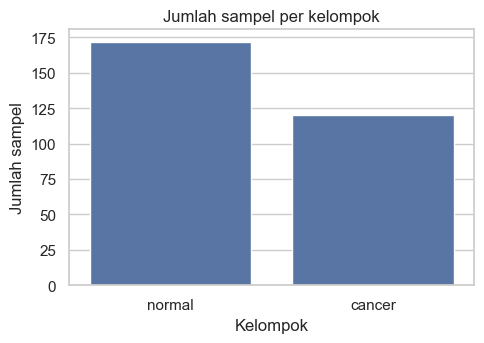

In [5]:
def read_fastq(path):
    """Baca FASTQ(.gz) utuh; kembalikan list sekuens & kualitas (bytes) setelah validasi format."""
    with gzip.open(path, "rb") as handle:
        lines = handle.read().split(b"\n")
    if lines and lines[-1] == b"":
        lines = lines[:-1]
    if len(lines) % 4:
        raise ValueError(f"{path.name}: jumlah baris bukan kelipatan 4")
    heads, seqs, plus, quals = lines[0::4], lines[1::4], lines[2::4], lines[3::4]
    if not all(h[:1] == b"@" for h in heads) or not all(p[:1] == b"+" for p in plus):
        raise ValueError(f"{path.name}: header FASTQ tidak valid")
    if any(len(s) != len(q) for s, q in zip(seqs, quals)):
        raise ValueError(f"{path.name}: panjang sekuens dan kualitas berbeda")
    return seqs, quals

example = cohort.index[0]
with gzip.open(cohort.loc[example, "r1_path"], "rt") as handle:
    print(f"Dua record pertama {cohort.loc[example, 'r1_path'].name}:\n")
    for _ in range(8):
        print(handle.readline().rstrip()[:110])

summary_table = pd.DataFrame({
    "jumlah_sampel": cohort.label.value_counts(),
    "total_read_pasangan": cohort.groupby("label").read_count.sum(),
    "median_read_per_sampel": cohort.groupby("label").read_count.median(),
})
display(summary_table)
print("Missing label:", int(cohort.label.isna().sum()), "| total basa (R1+R2):",
      f"{cohort.base_count.sum() / 1e9:.2f} Gbp")
fig, ax = plt.subplots(figsize=(5, 3.6))
sns.countplot(data=cohort, x="label", order=["normal", "cancer"], ax=ax)
ax.set(title="Jumlah sampel per kelompok", xlabel="Kelompok", ylabel="Jumlah sampel")
fig.tight_layout(); fig.savefig(RESULTS / "01_jumlah_sampel.png", dpi=180)
plt.show(); plt.close("all")

## 6. Quality control read mentah, filter, rarefaction, dan ekstraksi fitur
Berbeda dari data tabel yang sudah diproses, FASTQ memungkinkan **QC read mentah**. Untuk setiap sampel:

1. **QC R1 & R2:** jumlah read, panjang read, rerata skor Phred, kualitas per posisi, GC%, persentase basa N.
2. **Filter kualitas (R1):** potong ke 200 bp pertama, buang read yang mengandung `N` atau
   *expected errors* > 2 (EE = Σ 10^(−Q/10)).
3. **Rarefaction:** ambil acak 10.000 read lolos-filter (seed tetap) agar kedalaman setara; sampel dengan
   read lolos < 10.000 dikeluarkan dan dicatat.
4. **Fitur:** (a) **ESV** (*exact sequence variant*: sekuens 200 bp identik dihitung), dan
   (b) **frekuensi k-mer** (k = 6) — dua representasi sekuens untuk dibandingkan.

R2 hanya dipakai untuk QC: kualitasnya lebih rendah (lihat grafik), dan R1 200 bp sudah mencakup
sebagian besar region V4. Sel ini paling lama (beberapa menit) karena membaca seluruh FASTQ.

In [6]:
BASE_LUT = np.full(256, 4, dtype=np.uint8)
for index, base in enumerate(b"ACGT"):
    BASE_LUT[base] = index
KMER_WEIGHTS = 4 ** np.arange(KMER_K - 1, -1, -1)
POS_LEN = 250                                   # posisi yang diringkas untuk grafik kualitas


def read_qc(seqs, quals):
    """Statistik QC dasar dan rerata kualitas per posisi (250 posisi pertama)."""
    joined = b"".join(seqs)
    qual = np.frombuffer(b"".join(quals), np.uint8).astype(np.int16) - 33
    long_q = [q[:POS_LEN] for q in quals if len(q) >= POS_LEN]
    pos = (np.frombuffer(b"".join(long_q), np.uint8).reshape(-1, POS_LEN).astype(np.int16) - 33).mean(0)
    return dict(n_reads=len(seqs), mean_len=float(np.mean([len(s) for s in seqs])),
                mean_q=float(qual.mean()), pct_q30=float((qual >= 30).mean() * 100),
                gc_pct=(joined.count(b"G") + joined.count(b"C")) / len(joined) * 100,
                n_pct=joined.count(b"N") / len(joined) * 100), pos


def filter_reads(seqs, quals):
    """Potong ke TRUNC_LEN, buang read ber-N atau expected errors > MAX_EE."""
    keep = [i for i, s in enumerate(seqs) if len(s) >= TRUNC_LEN]
    S = np.frombuffer(b"".join(seqs[i][:TRUNC_LEN] for i in keep), np.uint8).reshape(-1, TRUNC_LEN)
    Q = np.frombuffer(b"".join(quals[i][:TRUNC_LEN] for i in keep), np.uint8).reshape(-1, TRUNC_LEN)
    expected_errors = (10.0 ** (-(Q.astype(float) - 33) / 10)).sum(axis=1)
    passed = (expected_errors <= MAX_EE) & ~(S == ord("N")).any(axis=1)
    return S[passed], expected_errors


def kmer_counts(S):
    """Hitung semua k-mer (tumpang-tindih) dari matriks read; dikodekan basis-4."""
    codes = BASE_LUT[S].astype(np.int64)
    width = S.shape[1] - KMER_K + 1
    index = sum(codes[:, j:j + width] * KMER_WEIGHTS[j] for j in range(KMER_K))
    return np.bincount(index.ravel(), minlength=4 ** KMER_K)


rng = np.random.default_rng(SEED)
qc_rows, esv_counts, kmer_rows, pos_quality = [], {}, {}, {"R1": {}, "R2": {}}
started = time.time()
for number, (run, row) in enumerate(cohort.iterrows(), 1):
    seqs, quals = read_fastq(row.r1_path)
    stats_r1, pos_quality["R1"][run] = read_qc(seqs, quals)
    starts_tac = np.mean([s[:3] == b"TAC" for s in seqs]) * 100
    passed, _ = filter_reads(seqs, quals)
    del seqs, quals
    seqs2, quals2 = read_fastq(row.r2_path)
    stats_r2, pos_quality["R2"][run] = read_qc(seqs2, quals2)
    del seqs2, quals2
    qc_row = dict(run=run, label=row.label, **{f"R1_{k}": v for k, v in stats_r1.items()},
                  **{f"R2_{k}": v for k, v in stats_r2.items()},
                  R1_pct_start_TAC=starts_tac, n_pass_filter=len(passed))
    qc_row["pct_pass_filter"] = qc_row["n_pass_filter"] / stats_r1["n_reads"] * 100
    qc_rows.append(qc_row)
    if len(passed) >= RAREFY_DEPTH:
        rare = passed[rng.choice(len(passed), RAREFY_DEPTH, replace=False)]
        esv_counts[run] = Counter(rare.view(f"S{TRUNC_LEN}").ravel().tolist())
        kmer_rows[run] = kmer_counts(rare)
    if number % 50 == 0 or number == len(cohort):
        print(f"{number}/{len(cohort)} sampel diproses ({time.time() - started:.0f} s)")

qc = pd.DataFrame(qc_rows).set_index("run")
qc["rarefied"] = qc.index.isin(list(esv_counts))
qc.to_csv(RESULTS / "qc_fastq_per_sampel.csv")

50/292 sampel diproses (44 s)


100/292 sampel diproses (86 s)


150/292 sampel diproses (125 s)


200/292 sampel diproses (177 s)


250/292 sampel diproses (221 s)


292/292 sampel diproses (262 s)


label                     cancer     normal
R1_n_reads       mean   56290.32   54408.99
                 min    13116.00   15011.00
                 max   259084.00  206528.00
R1_mean_q        mean      34.80      34.60
                 min       32.22      32.36
                 max       35.75      35.70
R1_pct_q30       mean      88.98      88.03
                 min       76.58      78.02
                 max       92.88      92.61
R2_mean_q        mean      32.92      32.72
                 min       29.20      29.23
                 max       34.70      34.99
R2_pct_q30       mean      80.00      78.93
                 min       62.53      62.59
                 max       88.10      89.30
R1_gc_pct        mean      52.51      52.27
                 min       47.03      49.39
                 max       56.33      57.17
R1_n_pct         mean       0.00       0.00
                 min        0.00       0.00
                 max        0.01       0.01
R1_pct_start_TAC mean      92.55      91.64
                 min       75.80      69.72
                 max       99.44      99.44
pct_pass_filter  mean      96.37      96.91
                 min       75.37      93.03
                 max       98.49      98.35

Dikeluarkan karena read lolos < 10000: 0 sampel {}


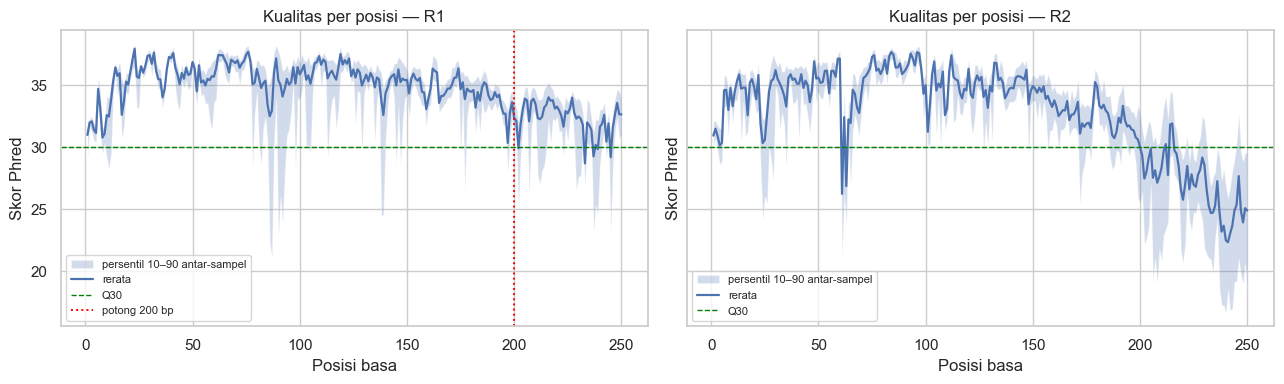

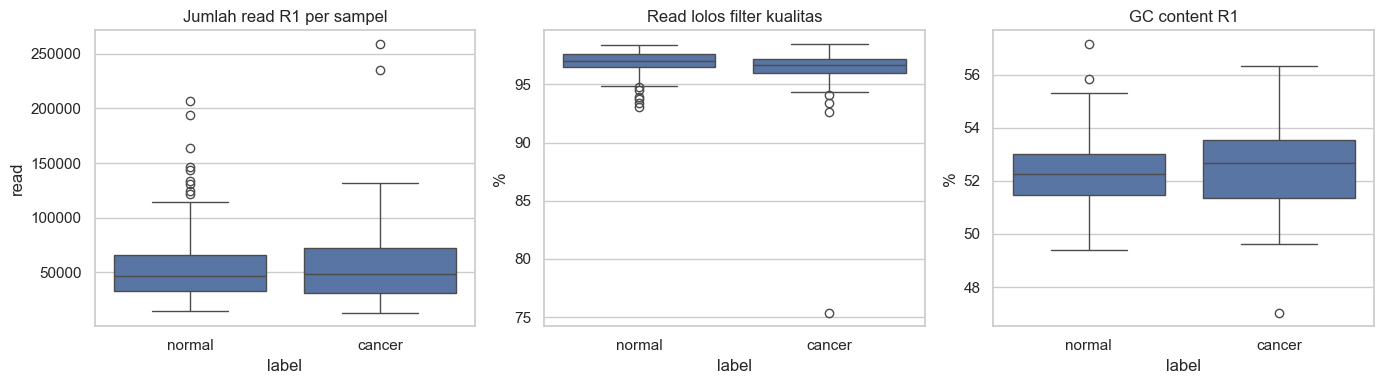

In [7]:
qc_cols = ["R1_n_reads", "R1_mean_q", "R1_pct_q30", "R2_mean_q", "R2_pct_q30", "R1_gc_pct",
           "R1_n_pct", "R1_pct_start_TAC", "pct_pass_filter"]
display(qc.groupby("label")[qc_cols].agg(["mean", "min", "max"]).round(2).T)
excluded = qc.loc[~qc.rarefied, ["label", "R1_n_reads", "n_pass_filter"]]
print(f"Dikeluarkan karena read lolos < {RAREFY_DEPTH}: {len(excluded)} sampel",
      excluded.label.value_counts().to_dict())
excluded.to_csv(RESULTS / "sampel_dikeluarkan_kedalaman.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axis, read in zip(axes, ["R1", "R2"]):
    matrix = np.vstack(list(pos_quality[read].values()))
    x = np.arange(1, POS_LEN + 1)
    axis.fill_between(x, np.percentile(matrix, 10, 0), np.percentile(matrix, 90, 0), alpha=.25,
                      label="persentil 10–90 antar-sampel")
    axis.plot(x, matrix.mean(0), lw=1.6, label="rerata")
    axis.axhline(30, color="green", ls="--", lw=1, label="Q30")
    if read == "R1":
        axis.axvline(TRUNC_LEN, color="red", ls=":", lw=1.4, label=f"potong {TRUNC_LEN} bp")
    axis.set(title=f"Kualitas per posisi — {read}", xlabel="Posisi basa", ylabel="Skor Phred")
    axis.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "02_kualitas_per_posisi.png", dpi=180)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(data=qc, x="label", y="R1_n_reads", order=["normal", "cancer"], ax=axes[0])
sns.boxplot(data=qc, x="label", y="pct_pass_filter", order=["normal", "cancer"], ax=axes[1])
sns.boxplot(data=qc, x="label", y="R1_gc_pct", order=["normal", "cancer"], ax=axes[2])
axes[0].set(title="Jumlah read R1 per sampel", ylabel="read")
axes[1].set(title="Read lolos filter kualitas", ylabel="%")
axes[2].set(title="GC content R1", ylabel="%")
fig.tight_layout(); fig.savefig(RESULTS / "03_qc_per_kelompok.png", dpi=180)
plt.show(); plt.close("all")

## 7. Tabel fitur: ESV dan k-mer
**ESV** dinamai berdasarkan kelimpahan total (`ESV0001` = paling melimpah). Filter global tanpa label:
ESV dipertahankan bila totalnya ≥ 10 read dan muncul di ≥ 2 sampel (membuang sebagian besar varian
akibat galat sekuensing). Filter prevalensi berbasis 10% dilakukan kemudian **di dalam training fold**.
Bagian ini juga menjawab ringkasan data seperti contoh kelas: jumlah fitur, persentase nol, rentang nilai.

ESV unik sebelum filter: 458,107; setelah filter global: 12,192
Proporsi read rarefied yang tercakup ESV terpilih: 79.0%
Sampel untuk analisis: 292 {'normal': 172, 'cancer': 120}
Tabel ESV  : (292, 12192), missing 0, rentang 0–3639, persentase nol 93.18%
Tabel k-mer: (292, 4096), rentang 0–19805, persentase nol 9.40%


,ESV0001,ESV0002,ESV0003,ESV0004,ESV0005,ESV0006,ESV0007,ESV0008,label
run,,,,,,,,,
SRR2143516,171,100,48,82,23,75,32,0,normal
SRR2143517,219,242,1,27,13,225,34,0,normal
SRR2143518,94,544,508,181,41,93,501,7,normal
SRR2143521,871,1,2,813,199,3,398,1,normal
SRR2143522,72,194,39,141,37,122,60,2,normal


esv_terdeteksi                                                       \
                count    mean     std    min     25%    50%    75%     max   
label                                                                        
cancer          120.0  788.23  116.93  418.0  723.25  793.0  851.5  1253.0   
normal          172.0  862.17  179.94  398.0  752.00  828.5  942.0  1311.0   

       shannon                                            
         count  mean   std   min   25%   50%   75%   max  
label                                                     
cancer   120.0  4.40  0.41  3.27  4.15  4.40  4.67  5.75  
normal   172.0  4.61  0.57  3.09  4.23  4.62  4.89  5.89

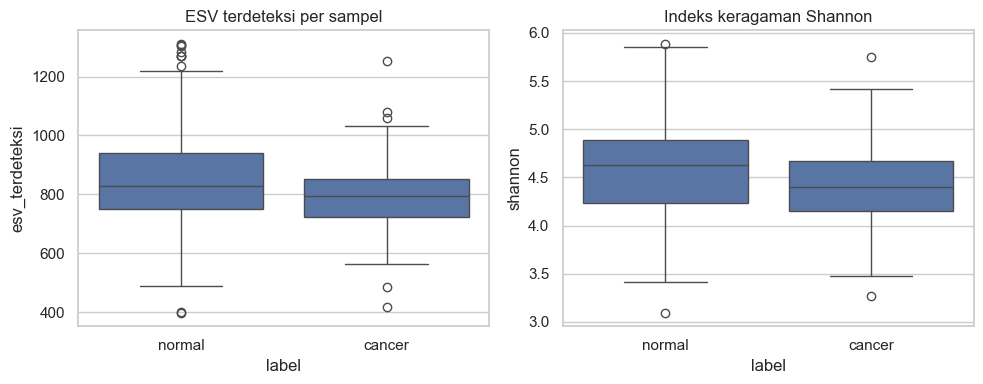

In [8]:
samples = list(esv_counts)
# from_dict(orient="index") dengan dict bersarang TIDAK menjamin urutan baris = urutan input,
# sehingga baris dikunci eksplisit dengan reindex(samples) agar tidak tertukar antarsampel.
esv_raw = pd.DataFrame.from_dict(esv_counts, orient="index").reindex(samples).fillna(0).astype(np.int32)
keep = (esv_raw.sum() >= 10) & ((esv_raw > 0).sum() >= 2)
esv_seq = esv_raw.loc[:, keep]
esv_seq = esv_seq.loc[:, esv_seq.sum().sort_values(ascending=False).index]

# Validasi: hitung ulang 5 sampel acak langsung dari Counter-nya; harus identik dengan baris tabel.
for run in np.random.default_rng(SEED).choice(samples, 5, replace=False):
    assert all(esv_seq.loc[run, seq] == esv_counts[run][seq] for seq in esv_seq.columns[:50]), run

sequences = [s.decode() for s in esv_seq.columns]
esv_ids = [f"ESV{i:04d}" for i in range(1, len(sequences) + 1)]
esv = pd.DataFrame(esv_seq.to_numpy(), index=esv_seq.index, columns=esv_ids)
esv.index.name = "run"
esv_fasta = dict(zip(esv_ids, sequences))
kmer_names = ["".join("ACGT"[(code // 4 ** p) % 4] for p in range(KMER_K - 1, -1, -1))
              for code in range(4 ** KMER_K)]
kmer = pd.DataFrame.from_dict(kmer_rows, orient="index", columns=kmer_names).loc[samples]
labels = cohort.loc[samples, "label"]
y = labels.eq("cancer").astype(int).to_numpy()

print(f"ESV unik sebelum filter: {esv_raw.shape[1]:,}; setelah filter global: {esv.shape[1]:,}")
print(f"Proporsi read rarefied yang tercakup ESV terpilih: {esv.sum(1).mean() / RAREFY_DEPTH:.1%}")
print(f"Sampel untuk analisis: {len(samples)}", labels.value_counts().to_dict())
print(f"Tabel ESV  : {esv.shape}, missing {int(esv.isna().sum().sum())}, rentang {esv.min().min()}–{esv.max().max()}, "
      f"persentase nol {(esv == 0).mean().mean():.2%}")
print(f"Tabel k-mer: {kmer.shape}, rentang {kmer.min().min()}–{kmer.max().max()}, "
      f"persentase nol {(kmer == 0).mean().mean():.2%}")
display(esv.iloc[:5, :8].assign(label=labels.iloc[:5]))

relative = esv.div(RAREFY_DEPTH) * 100                       # kelimpahan relatif (%)
diversity = pd.DataFrame({
    "label": labels,
    "esv_terdeteksi": (esv > 0).sum(1),
    "shannon": -(esv.div(esv.sum(1), axis=0).replace(0, np.nan)
                 .pipe(lambda p: p * np.log(p))).sum(1),
})
display(diversity.groupby("label")[["esv_terdeteksi", "shannon"]].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=diversity, x="label", y="esv_terdeteksi", order=["normal", "cancer"], ax=axes[0])
sns.boxplot(data=diversity, x="label", y="shannon", order=["normal", "cancer"], ax=axes[1])
axes[0].set(title="ESV terdeteksi per sampel"); axes[1].set(title="Indeks keragaman Shannon")
fig.tight_layout(); fig.savefig(RESULTS / "04_keragaman.png", dpi=180)
plt.show(); plt.close("all")

esv.to_csv(RESULTS / "tabel_fitur_esv.csv")
kmer.to_csv(RESULTS / "tabel_fitur_kmer.csv.gz", compression="gzip")
with open(RESULTS / "esv_sequences.fasta", "w") as handle:
    handle.writelines(f">{name}\n{seq}\n" for name, seq in esv_fasta.items())

## 8. Anotasi taksonomi ESV terhadap referensi FASTA NCBI 16S RefSeq
**Metode:** dari setiap sekuens referensi, cari primer 515F (`GTGYCAGCMGCCGCGGTAA`) lalu ambil 200 bp
sesudahnya — posisi yang sama dengan awal read. ESV yang identik dengan potongan referensi diberi
genus referensi tersebut; bila tidak identik, dipakai referensi dengan jumlah ketidakcocokan basa paling
sedikit (*nearest reference*). Genus hanya ditetapkan bila identitas ≥ 97%; di bawahnya ditandai
`unclassified`. Region V4 tidak cukup untuk memastikan spesies, sehingga analisis memakai tingkat genus.
Referensi RefSeq diperbarui berkala; SHA256 versi yang dipakai dicatat di manifest.

In [9]:
REF_URL = "https://ftp.ncbi.nlm.nih.gov/refseq/TargetedLoci/Bacteria/bacteria.16SrRNA.fna.gz"
REF_PATH = REF_DIR / "bacteria.16SrRNA.fna.gz"
if not REF_PATH.exists():
    request = urllib.request.Request(REF_URL, headers=USER_AGENT)
    with urllib.request.urlopen(request, timeout=300) as response:
        payload = response.read()
    gzip.decompress(payload)                                   # validasi gzip sebelum disimpan
    REF_PATH.write_bytes(payload)
ref_sha256 = hashlib.sha256(REF_PATH.read_bytes()).hexdigest()

ref_names, ref_seqs, name, chunks = [], [], None, []
with gzip.open(REF_PATH, "rt") as handle:
    for line in handle:
        if line.startswith(">"):
            if name:
                ref_names.append(name); ref_seqs.append("".join(chunks).upper())
            name, chunks = line[1:].strip(), []
        else:
            chunks.append(line.strip())
    ref_names.append(name); ref_seqs.append("".join(chunks).upper())

primer = re.compile("GTG[CT]CAGC[AC]GCCGCGGTAA")
v4_seq, v4_taxon = [], []
for header, seq in zip(ref_names, ref_seqs):
    match = primer.search(seq)
    fragment = seq[match.end():match.end() + TRUNC_LEN] if match else ""
    if len(fragment) == TRUNC_LEN and set(fragment) <= set("ACGT"):
        v4_seq.append(fragment)
        v4_taxon.append(" ".join(header.split()[1:3]))         # "Genus species"
print(f"Referensi: {len(ref_seqs):,} sekuens 16S; {len(v4_seq):,} memiliki region V4 lengkap")

ref_matrix = np.frombuffer("".join(v4_seq).encode(), np.uint8).reshape(-1, TRUNC_LEN)
ref_genus = np.array([taxon.split()[0] for taxon in v4_taxon])
query = np.frombuffer("".join(sequences).encode(), np.uint8).reshape(-1, TRUNC_LEN)
best_mm, best_genus, best_taxon = [], [], []
for start in range(0, len(query), 16):                         # batch agar hemat memori
    mismatches = (query[start:start + 16, None, :] != ref_matrix[None, :, :]).sum(axis=2)
    for row in mismatches:
        minimum = row.min(); hits = np.flatnonzero(row == minimum)
        genera = Counter(ref_genus[hits])
        best_mm.append(minimum)
        best_genus.append("/".join(sorted(genera)) if len(genera) <= 2 else genera.most_common(1)[0][0])
        best_taxon.append(v4_taxon[hits[0]])

taxonomy = pd.DataFrame({"sequence": sequences, "nearest_reference": best_taxon,
                         "identity_pct": 100 * (1 - np.array(best_mm) / TRUNC_LEN), "genus_hit": best_genus},
                        index=esv_ids)
taxonomy["genus"] = np.where(taxonomy.identity_pct >= 97, taxonomy.genus_hit, "unclassified")
taxonomy["label_fitur"] = taxonomy.genus.str.replace("unclassified", "uncl.") + " (" + taxonomy.index + ")"
taxonomy.to_csv(RESULTS / "taksonomi_esv.csv")
classified_reads = esv.loc[:, taxonomy.genus.ne("unclassified")].sum().sum() / esv.sum().sum()
print(f"ESV terklasifikasi genus (identitas ≥97%): {taxonomy.genus.ne('unclassified').mean():.1%} ESV, "
      f"{classified_reads:.1%} read")
display(taxonomy.head(10)[["genus", "nearest_reference", "identity_pct"]]
        .assign(rerata_kelimpahan_pct=relative.mean().head(10).round(2)))

Referensi: 26,888 sekuens 16S; 25,368 memiliki region V4 lengkap


ESV terklasifikasi genus (identitas ≥97%): 78.8% ESV, 84.8% read


,genus,nearest_reference,identity_pct,rerata_kelimpahan_pct
ESV0001,Blautia,Blautia provencensis,100.0,4.38
ESV0002,Phocaeicola,Phocaeicola vulgatus,100.0,1.87
ESV0003,Bacteroides,Bacteroides uniformis,100.0,1.76
ESV0004,Agathobacter,Agathobacter rectalis,100.0,1.74
ESV0005,Blautia,Blautia intestinalis,97.0,1.67
ESV0006,Bacteroides,Bacteroides luhongzhouii,100.0,1.47
ESV0007,Anaerostipes,Anaerostipes hadrus,100.0,1.43
ESV0008,Akkermansia,Akkermansia muciniphila,100.0,1.34
ESV0009,Fusicatenibacter,Fusicatenibacter saccharivorans,100.0,1.24
ESV0010,Faecalibacterium,Faecalibacterium butyricigenerans,100.0,1.16


### 8b. Validasi silang dengan data olahan penulis
Pipeline Python di notebook ini berbeda dari pipeline asli penulis (mothur, OTU 97%). Untuk memastikan
fitur kita benar-benar mewakili sampel yang sama, profil kita dibandingkan dengan tabel OTU yang
dipublikasikan penulis di GitHub (Schloss Lab). Bila tautan sampel dan pemrosesan benar, keragaman
Shannon dan kelimpahan taksa dominan antarsampel harus berkorelasi kuat; bila baris tertukar,
korelasinya mendekati nol. Pemeriksaan ini hanya kontrol kualitas: data penulis tidak dipakai di model.

In [10]:
from scipy.stats import spearmanr

AUTHOR_URL = ("https://raw.githubusercontent.com/SchlossLab/Baxter_glne007Modeling_GenomeMed_2015/master/"
              "data/glne007.final.an.unique_list.0.03.subsample.0.03.filter.shared")


def shannon_index(counts):
    proportion = counts.div(counts.sum(1), axis=0).replace(0, np.nan)
    return -(proportion * np.log(proportion)).sum(1)


try:
    author_path = REF_DIR / "penulis_otu_0.03.shared"
    if not author_path.exists():
        author_path.write_bytes(urllib.request.urlopen(
            urllib.request.Request(AUTHOR_URL, headers=USER_AGENT), timeout=120).read())
    author = (pd.read_csv(author_path, sep="\t", dtype={"Group": str}).set_index("Group")
              .drop(columns=["label", "numOtus"]))
    sample_ids = cohort.loc[samples, "sample_title"].astype(str)
    matched = sample_ids.isin(author.index).to_numpy()
    author_rows = author.loc[sample_ids[matched]]
    rho_shannon = spearmanr(shannon_index(esv[matched]).values, shannon_index(author_rows).values)[0]
    # Untuk 20 OTU penulis teratas, cari ESV kita dengan korelasi kelimpahan antarsampel tertinggi.
    rank_a = author_rows.iloc[:, :20].rank().to_numpy(); rank_b = esv[matched].iloc[:, :300].rank().to_numpy()
    rank_a = (rank_a - rank_a.mean(0)) / rank_a.std(0); rank_b = (rank_b - rank_b.mean(0)) / rank_b.std(0)
    best_match = (rank_a.T @ rank_b / len(rank_a)).max(axis=1)
    print(f"Sampel cocok dengan tabel penulis: {matched.sum()} / {len(samples)}")
    print(f"Spearman keragaman Shannon (kita vs penulis): {rho_shannon:.3f}")
    print(f"Korelasi terbaik 20 OTU teratas penulis dengan ESV kita: median {np.median(best_match):.3f}, "
          f"min {best_match.min():.3f}")
    validation = {"shannon_spearman": round(float(rho_shannon), 4),
                  "otu_best_match_median": round(float(np.median(best_match)), 4)}
except Exception as exc:                     # validasi opsional; analisis tetap berjalan bila GitHub tidak terjangkau
    print("Validasi silang dilewati:", type(exc).__name__, exc)
    validation = {"status": "dilewati"}

Sampel cocok dengan tabel penulis: 292 / 292
Spearman keragaman Shannon (kita vs penulis): 0.806
Korelasi terbaik 20 OTU teratas penulis dengan ESV kita: median 0.884, min 0.405


## 9. Visualisasi taksa terpilih
Genus yang dalam literatur sering dikaitkan dengan kanker kolorektal (*Fusobacterium*, *Parvimonas*,
*Peptostreptococcus*, *Porphyromonas*, *Gemella*) dibandingkan dengan genus komensal umum
(*Faecalibacterium*, *Roseburia*, *Bacteroides*). Kelimpahan genus = jumlah ESV dengan genus tersebut.
Sumbu-y memakai skala log karena banyak sampel bernilai nol (ditampilkan pada 0,001%).
Pemilihan genus ini berasal dari literatur, bukan dari hasil uji di notebook. Tabel hitungan per genus
juga disiapkan sebagai **representasi fitur Genus** untuk machine learning.

Tabel genus: 280 genus; persentase nol 70.90%


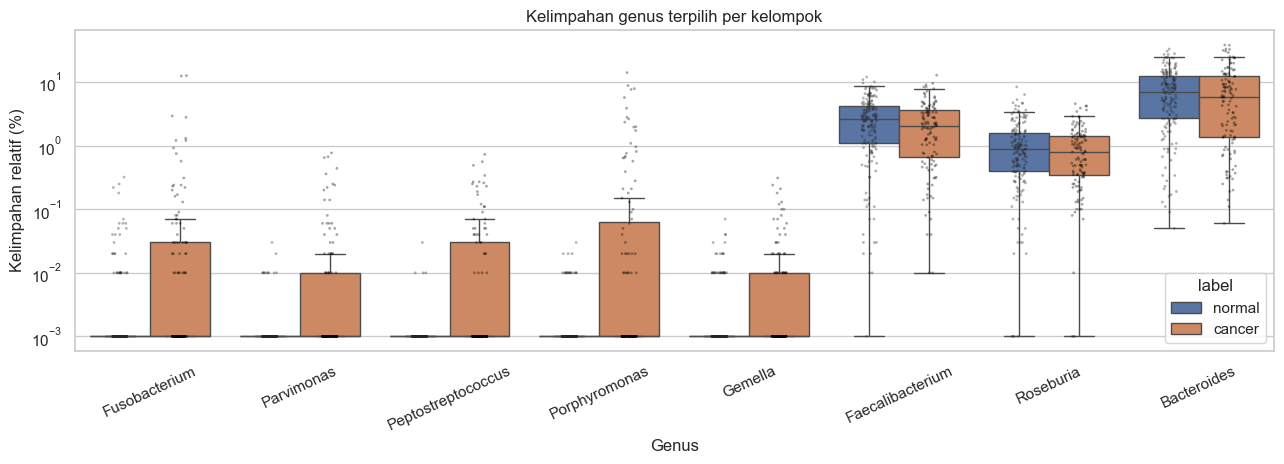

genus,Fusobacterium,Parvimonas,Peptostreptococcus,Porphyromonas,Gemella,Faecalibacterium,Roseburia,Bacteroides
prevalensi_% (sampel dengan genus terdeteksi),,,,,,,,
cancer,42.5,30.0,31.7,39.2,34.2,100.0,98.3,100.0
normal,19.2,6.4,2.3,11.6,19.8,99.4,97.7,100.0


In [11]:
genus_table = relative.T.groupby(taxonomy.genus).sum().T
genus_table.to_csv(RESULTS / "kelimpahan_genus.csv")
# Tabel hitungan per genus (tanpa 'unclassified') menjadi representasi fitur ketiga untuk model.
genus_counts = esv.T.groupby(taxonomy.genus).sum().T.drop(columns="unclassified", errors="ignore")
print(f"Tabel genus: {genus_counts.shape[1]} genus; persentase nol {(genus_counts == 0).mean().mean():.2%}")
SELECTED_GENERA = ["Fusobacterium", "Parvimonas", "Peptostreptococcus", "Porphyromonas", "Gemella",
                   "Faecalibacterium", "Roseburia", "Bacteroides"]
present = [g for g in SELECTED_GENERA if g in genus_table.columns]
long = (genus_table[present].clip(lower=1e-3).assign(label=labels)
        .melt(id_vars="label", var_name="genus", value_name="kelimpahan_pct"))
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.boxplot(data=long, x="genus", y="kelimpahan_pct", hue="label", hue_order=["normal", "cancer"],
            showfliers=False, ax=ax)
sns.stripplot(data=long, x="genus", y="kelimpahan_pct", hue="label", hue_order=["normal", "cancer"],
              dodge=True, size=2, alpha=.35, legend=False, ax=ax, palette="dark:black")
ax.set_yscale("log"); ax.set(xlabel="Genus", ylabel="Kelimpahan relatif (%)",
                             title="Kelimpahan genus terpilih per kelompok")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout(); fig.savefig(RESULTS / "05_genus_terpilih.png", dpi=180)
plt.show(); plt.close("all")
display((genus_table[present].gt(0).groupby(labels).mean() * 100).round(1)
        .rename_axis("prevalensi_% (sampel dengan genus terdeteksi)"))

## 10. Principal Component Analysis (PCA)
**Input:** ESV dengan prevalensi ≥ 10%, ditransformasi **CLR** (*centered log-ratio*): log(hitungan + 0,5)
dikurangi rerata log per sampel. CLR adalah transformasi standar untuk data komposisi seperti mikrobioma
(jumlah per sampel dibuat tetap oleh rarefaction). Label tidak dipakai. Pemisahan visual bukan akurasi.

Fitur PCA: 1878 ESV; PC1 6.14%, PC2 5.80%, 10 PC 27.76%


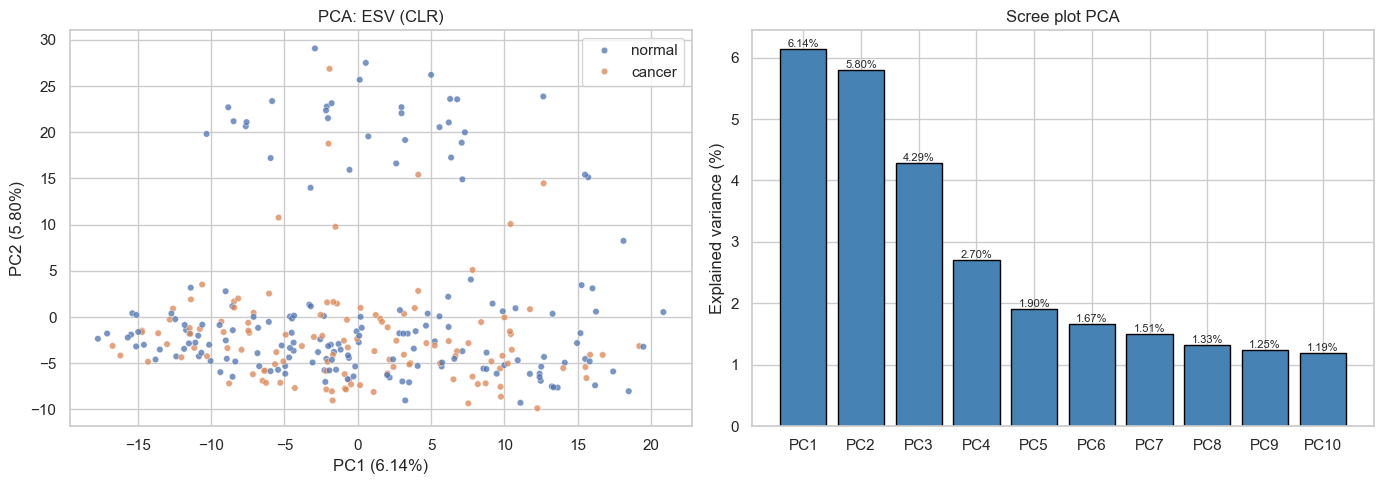

In [12]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

def clr(counts):
    logged = np.log(np.asarray(counts, dtype=float) + 0.5)
    return logged - logged.mean(axis=1, keepdims=True)

pca_features = esv.columns[(esv > 0).mean() >= MIN_PREVALENCE]
Z_clr = clr(esv[pca_features])
pca = PCA(n_components=10, random_state=SEED)
scores = pca.fit_transform(Z_clr - Z_clr.mean(0))
evr = pca.explained_variance_ratio_
pd.DataFrame({"PC": np.arange(1, 11), "explained_variance": evr, "kumulatif": evr.cumsum()}
             ).to_csv(RESULTS / "pca_variance.csv", index=False)
print(f"Fitur PCA: {len(pca_features)} ESV; PC1 {evr[0]:.2%}, PC2 {evr[1]:.2%}, 10 PC {evr.sum():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=labels.to_numpy(), hue_order=["normal", "cancer"],
                s=22, alpha=.75, ax=axes[0])
axes[0].set(xlabel=f"PC1 ({evr[0]:.2%})", ylabel=f"PC2 ({evr[1]:.2%})", title="PCA: ESV (CLR)")
bars = axes[1].bar([f"PC{i}" for i in range(1, 11)], evr * 100, color="steelblue", edgecolor="black")
axes[1].bar_label(bars, fmt="%.2f%%", fontsize=8)
axes[1].set(ylabel="Explained variance (%)", title="Scree plot PCA")
fig.tight_layout(); fig.savefig(RESULTS / "06_pca.png", dpi=180)
plt.show(); plt.close("all")

## 11. Grafik elbow dan K-Means clustering
**Input:** 10 komponen PCA. **Elbow:** inertia (WCSS) untuk k = 1–15. **K-Means:** k = 2 (dua kelompok
yang diharapkan), lalu dibandingkan dengan label melalui crosstab dan *Adjusted Rand Index* (ARI;
0 = tidak lebih baik dari acak, 1 = identik). Cluster tidak harus sama dengan kelompok penyakit.

Label,cancer,normal
Cluster,,
0,7,34
1,113,138


K-Means k=2: silhouette 0.279, ARI terhadap label -0.018


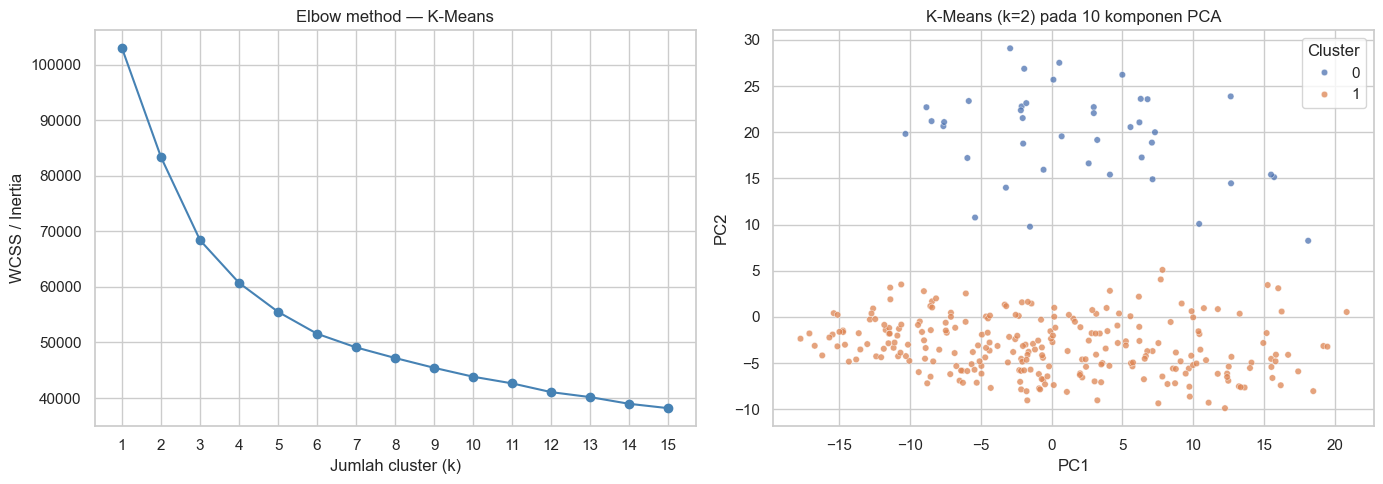

In [13]:
inertia = [KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(scores).inertia_ for k in range(1, 16)]
kmeans = KMeans(n_clusters=2, n_init=50, random_state=SEED).fit(scores)
clusters = kmeans.labels_
ari = adjusted_rand_score(y, clusters)
silhouette = silhouette_score(scores, clusters)
pd.DataFrame({"k": range(1, 16), "inertia": inertia}).to_csv(RESULTS / "kmeans_elbow.csv", index=False)
display(pd.crosstab(pd.Series(clusters, name="Cluster"), labels.rename("Label").reset_index(drop=True)))
print(f"K-Means k=2: silhouette {silhouette:.3f}, ARI terhadap label {ari:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, 16), inertia, "o-", color="steelblue")
axes[0].set(xticks=range(1, 16), xlabel="Jumlah cluster (k)", ylabel="WCSS / Inertia",
            title="Elbow method — K-Means")
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=clusters.astype(str), s=22, alpha=.75, ax=axes[1])
axes[1].set(xlabel="PC1", ylabel="PC2", title="K-Means (k=2) pada 10 komponen PCA")
axes[1].legend(title="Cluster")
fig.tight_layout(); fig.savefig(RESULTS / "07_elbow_kmeans.png", dpi=180)
plt.show(); plt.close("all")

## 12. Skrining kelimpahan berbeda: cancer vs normal
| Metode | Tujuan |
|---|---|
| Mann–Whitney U dua sisi | menguji apakah distribusi kelimpahan suatu ESV berbeda antara cancer dan normal |
| P-value | bukti statistik terhadap hipotesis tidak ada perbedaan distribusi |
| Benjamini–Hochberg (FDR) | mengendalikan proporsi penemuan palsu ketika ratusan ESV diuji sekaligus |
| Selisih rerata | arah dan besar perbedaan: selisih rerata log10(kelimpahan relatif % + 0,001) |

Uji dilakukan pada **kelimpahan relatif** dari data rarefied (kedalaman sama), bukan pada nilai CLR:
pada tabel yang sangat jarang (>90% nol), CLR menggeser semua fitur pada sampel berkeragaman rendah
sehingga menghasilkan "signifikansi" palsu. Uji dilakukan pada **tingkat genus** (tabel utama) dan
tingkat ESV (ringkasan). Hanya fitur dengan prevalensi ≥ 10% yang diuji. Uji tidak berpasangan tepat dipakai karena
setiap orang hanya menyumbang **satu** sampel feses, sehingga masalah pseudoreplikasi pada contoh data sel
tunggal tidak terjadi di sini. Hasil ini eksploratif dan tidak dipakai untuk memilih fitur model.

In [14]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

cancer_mask = labels.eq("cancer").to_numpy()


def mann_whitney_table(counts):
    """Mann-Whitney U dua sisi pada kelimpahan relatif (rarefied) + BH-FDR, fitur prevalensi ≥ MIN_PREVALENCE."""
    tested = counts.columns[(counts > 0).mean() >= MIN_PREVALENCE]
    pct = counts[tested].div(RAREFY_DEPTH) * 100
    log_pct = np.log10(pct + 1e-3)                              # skala log untuk effect size & heatmap
    result = pd.DataFrame({
        "mean_pct_cancer": pct[cancer_mask].mean(),
        "mean_pct_normal": pct[~cancer_mask].mean(),
        "mean_log10_difference": log_pct[cancer_mask].mean() - log_pct[~cancer_mask].mean(),
        "p_value": mannwhitneyu(pct[cancer_mask], pct[~cancer_mask], alternative="two-sided", axis=0).pvalue,
    }, index=tested)
    result["FDR_BH"] = multipletests(result.p_value, method="fdr_bh")[1]
    result["significant"] = result.FDR_BH < 0.05
    # BH dapat menghasilkan FDR kembar; p-value dipakai sebagai urutan kedua agar peringkat tetap bermakna.
    return result.sort_values(["FDR_BH", "p_value"]), log_pct


def describe(result, unit):
    up = int((result.significant & (result.mean_log10_difference > 0)).sum())
    down = int((result.significant & (result.mean_log10_difference < 0)).sum())
    print(f"{unit} diuji: {len(result)}; FDR < 0,05: {int(result.significant.sum())} "
          f"(lebih tinggi pada cancer: {up}, lebih tinggi pada normal: {down})")


diff, log_genus = mann_whitney_table(genus_counts)
diff_esv, _ = mann_whitney_table(esv)
diff_esv.insert(0, "genus", taxonomy.loc[diff_esv.index, "genus"])
diff.to_csv(RESULTS / "mann_whitney_genus.csv")
diff_esv.to_csv(RESULTS / "mann_whitney_esv.csv")
describe(diff, "Genus"); describe(diff_esv, "ESV")
display(diff.head(15).round({"mean_pct_cancer": 4, "mean_pct_normal": 4, "mean_log10_difference": 3}))

Genus diuji: 169; FDR < 0,05: 10 (lebih tinggi pada cancer: 8, lebih tinggi pada normal: 2)
ESV diuji: 1878; FDR < 0,05: 76 (lebih tinggi pada cancer: 12, lebih tinggi pada normal: 64)


,mean_pct_cancer,mean_pct_normal,mean_log10_difference,p_value,FDR_BH,significant
genus,,,,,,
Peptostreptococcus,0.0434,0.0003,0.564,1.000235e-12,1.690397e-10,True
Porphyromonas,0.5828,0.0015,0.790,7.950346e-10,6.718042e-08,True
Parvimonas,0.0403,0.0008,0.449,1.485148e-08,8.366335e-07,True
Fusobacterium,0.3324,0.0099,0.555,1.386617e-06,5.858459e-05,True
Haemophilus,0.0434,0.1881,-0.440,2.123921e-04,7.178855e-03,True
Evtepia,0.0794,0.0518,0.394,4.245780e-04,1.195895e-02,True
Gemella,0.0186,0.0033,0.277,1.147303e-03,2.769918e-02,True
Massiliprevotella,0.7174,0.0168,0.468,1.594470e-03,3.162720e-02,True
Klebsiella,0.3814,0.0445,0.348,1.684289e-03,3.162720e-02,True


## 13. Volcano-style plot dan heatmap
**Volcano-style plot** menjawab "genus mana yang paling menonjol perbedaannya?" (sumbu-x: selisih rerata
log10 kelimpahan relatif cancer − normal; sumbu-y: −log10 FDR). **Heatmap** menjawab "bagaimana pola
kelimpahan genus tersebut pada kedua kelompok?" (rerata log10 kelimpahan per kelompok, distandarkan per genus).

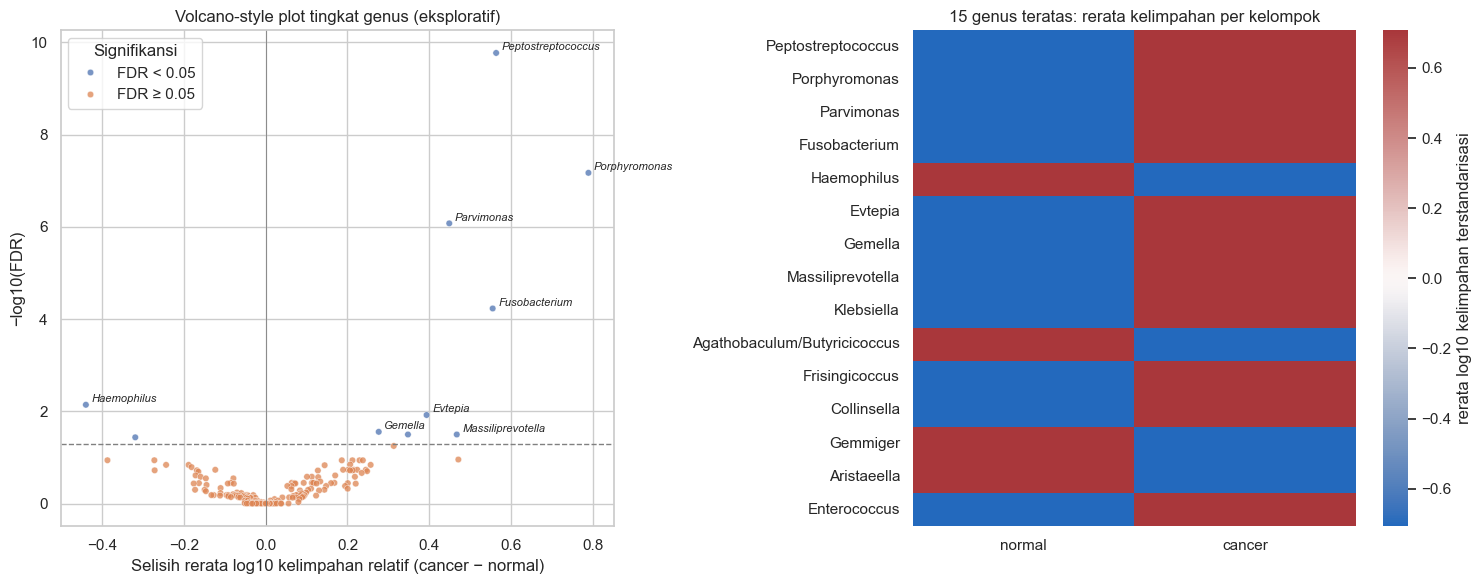

In [15]:
top = diff.head(15).index
fig = plt.figure(figsize=(15, 6))
ax_volcano = fig.add_subplot(1, 2, 1)
sns.scatterplot(data=diff, x="mean_log10_difference", y=-np.log10(diff.FDR_BH),
                hue=np.where(diff.significant, "FDR < 0.05", "FDR ≥ 0.05"),
                hue_order=["FDR < 0.05", "FDR ≥ 0.05"], s=22, alpha=.75, ax=ax_volcano)
ax_volcano.axhline(-np.log10(0.05), color="grey", ls="--", lw=1)
ax_volcano.axvline(0, color="grey", lw=.6)
for genus_name in diff.head(8).index:
    ax_volcano.annotate(genus_name, (diff.loc[genus_name, "mean_log10_difference"],
                                     -np.log10(diff.loc[genus_name, "FDR_BH"])),
                        fontsize=8, style="italic", xytext=(4, 2), textcoords="offset points")
ax_volcano.set(xlabel="Selisih rerata log10 kelimpahan relatif (cancer − normal)", ylabel="−log10(FDR)",
               title="Volcano-style plot tingkat genus (eksploratif)")
ax_volcano.legend(title="Signifikansi")

group_means = log_genus[top].groupby(labels.to_numpy()).mean().loc[["normal", "cancer"]].T
heat = group_means.sub(group_means.mean(1), axis=0).div(group_means.std(1), axis=0)
ax_heat = fig.add_subplot(1, 2, 2)
sns.heatmap(heat, cmap="vlag", center=0, ax=ax_heat, cbar_kws={"label": "rerata log10 kelimpahan terstandarisasi"})
ax_heat.set(title="15 genus teratas: rerata kelimpahan per kelompok", xlabel="", ylabel="")
fig.tight_layout(); fig.savefig(RESULTS / "08_volcano_heatmap.png", dpi=180)
plt.show(); plt.close("all")

## 14. Klasifikasi: data, model, dan pencegahan kebocoran data
**Data:** sampel × fitur (ESV atau k-mer) dengan label `cancer`/`normal`.

| Aspek | Logistic Regression | Random Forest |
|---|---|---|
| Pendekatan | model linear probabilistik | ensemble decision tree |
| Hubungan non-linear | terbatas tanpa rekayasa fitur | dapat dipelajari |
| StandardScaler | dipakai | tidak wajib |
| Interpretasi | koefisien fitur | feature importance |
| Risiko overfitting | dikendalikan regularisasi (C) | dikendalikan jumlah sampel daun dan fitur per split |
| Kelebihan | sederhana, cepat, baseline | fleksibel untuk pola kompleks |

**Pipeline** (dipelajari hanya dari data training): filter prevalensi ≥ 10% → CLR (stateless) →
StandardScaler (LR) → model. Kelas tidak seimbang ditangani `class_weight="balanced"`.
**Evaluasi:** split *stratified* 80% training / 20% test (test tidak disentuh selama tuning); tuning
`GridSearchCV` 5-fold pada training; ambang probabilitas 0,5. Tiga representasi sekuens dibandingkan:

| Representasi | Asal fitur | Kelebihan |
|---|---|---|
| **ESV** | hitungan sekuens 200 bp identik | resolusi tertinggi |
| **Genus** | ESV digabung per genus hasil anotasi FASTA | mudah ditafsirkan secara biologis, tidak terlalu jarang |
| **k-mer (k=6)** | frekuensi 4.096 kata 6 basa dari read | bebas referensi dan bebas alignment |

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay)


class PrevalenceFilter(BaseEstimator, TransformerMixin):
    """Simpan fitur yang muncul (>0) pada ≥ min_prevalence sampel training."""

    def __init__(self, min_prevalence=0.10):
        self.min_prevalence = min_prevalence

    def fit(self, X, y=None):
        self.support_ = (np.asarray(X) > 0).mean(axis=0) >= self.min_prevalence
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]


class CLRTransform(BaseEstimator, TransformerMixin):
    """Centered log-ratio per sampel; tidak mempelajari parameter dari data."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return clr(X)


MODEL_NAMES = ["Logistic Regression", "Random Forest"]


def make_model(name):
    steps = [("prevalence", PrevalenceFilter(MIN_PREVALENCE)), ("clr", CLRTransform())]
    if name == "Logistic Regression":
        steps += [("scale", StandardScaler()),
                  ("model", LogisticRegression(max_iter=5000, class_weight="balanced"))]
        grid = {"model__C": [0.001, 0.01, 0.1, 1]}
    else:
        steps += [("model", RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                                   n_jobs=-1, random_state=SEED))]
        grid = {"model__max_features": ["sqrt", 0.05], "model__min_samples_leaf": [1, 3]}
    return Pipeline(steps), grid


def metrics(y_true, prob):
    pred = (np.asarray(prob) >= 0.5).astype(int)
    return dict(Accuracy=accuracy_score(y_true, pred),
                Precision_cancer=precision_score(y_true, pred, zero_division=0),
                Recall_cancer=recall_score(y_true, pred, zero_division=0),
                F1_cancer=f1_score(y_true, pred, zero_division=0),
                Specificity=recall_score(y_true, pred, pos_label=0, zero_division=0),
                Balanced_accuracy=balanced_accuracy_score(y_true, pred),
                ROC_AUC=roc_auc_score(y_true, prob), PR_AUC=average_precision_score(y_true, prob))


FEATURE_SETS = {"ESV": esv, "Genus": genus_counts, "k-mer": kmer}
train_idx, test_idx = train_test_split(np.arange(len(samples)), test_size=0.2, stratify=y, random_state=SEED)
y_train, y_test = y[train_idx], y[test_idx]
write_json(RESULTS / "split_train_test.json",
           {"train": [samples[i] for i in train_idx], "test": [samples[i] for i in test_idx]})
print(f"Training: {len(train_idx)} sampel {np.bincount(y_train).tolist()} [normal, cancer]; "
      f"test: {len(test_idx)} sampel {np.bincount(y_test).tolist()}")
display(esv.iloc[:4, :5].assign(**{"...": "...", "label": labels.iloc[:4]}))

Training: 233 sampel [137, 96] [normal, cancer]; test: 59 sampel [35, 24]


,ESV0001,ESV0002,ESV0003,ESV0004,ESV0005,...,label
run,,,,,,,
SRR2143516,171,100,48,82,23,...,normal
SRR2143517,219,242,1,27,13,...,normal
SRR2143518,94,544,508,181,41,...,normal
SRR2143521,871,1,2,813,199,...,normal


In [17]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, test_prob, rows = {}, {}, []
for feature_name, table in FEATURE_SETS.items():
    X_all = table.to_numpy(dtype=float)
    for model_name in MODEL_NAMES:
        pipe, grid = make_model(model_name)
        search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="roc_auc", n_jobs=1)
        search.fit(X_all[train_idx], y_train)
        key = (feature_name, model_name)
        fitted[key] = search.best_estimator_
        test_prob[key] = search.predict_proba(X_all[test_idx])[:, 1]
        rows.append(dict(Fitur=feature_name, Model=model_name, **metrics(y_test, test_prob[key]),
                         Parameter=search.best_params_))
        print(f"{feature_name:6s} | {model_name:20s} | parameter terbaik {search.best_params_}")
baseline = DummyClassifier(strategy="prior").fit(esv.to_numpy()[train_idx], y_train)
rows.append(dict(Fitur="-", Model="Dummy (baseline)",
                 **metrics(y_test, baseline.predict_proba(esv.to_numpy()[test_idx])[:, 1]), Parameter={}))
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS / "perbandingan_model_test.csv", index=False)

for (feature_name, model_name), prob in test_prob.items():
    print(f"\n{model_name} — fitur {feature_name} — test set")
    print(classification_report(y_test, (prob >= 0.5).astype(int), target_names=["normal", "cancer"], digits=3))
display(comparison.drop(columns="Parameter").sort_values("ROC_AUC", ascending=False).round(4))

ESV    | Logistic Regression  | parameter terbaik {'model__C': 0.001}


ESV    | Random Forest        | parameter terbaik {'model__max_features': 0.05, 'model__min_samples_leaf': 1}
Genus  | Logistic Regression  | parameter terbaik {'model__C': 0.01}


Genus  | Random Forest        | parameter terbaik {'model__max_features': 'sqrt', 'model__min_samples_leaf': 3}


k-mer  | Logistic Regression  | parameter terbaik {'model__C': 0.001}


k-mer  | Random Forest        | parameter terbaik {'model__max_features': 0.05, 'model__min_samples_leaf': 3}

Logistic Regression — fitur ESV — test set
              precision    recall  f1-score   support

      normal      0.677     0.600     0.636        35
      cancer      0.500     0.583     0.538        24

    accuracy                          0.593        59
   macro avg      0.589     0.592     0.587        59
weighted avg      0.605     0.593     0.597        59


Random Forest — fitur ESV — test set
              precision    recall  f1-score   support

      normal      0.730     0.771     0.750        35
      cancer      0.636     0.583     0.609        24

    accuracy                          0.695        59
   macro avg      0.683     0.677     0.679        59
weighted avg      0.692     0.695     0.693        59


Logistic Regression — fitur Genus — test set
              precision    recall  f1-score   support

      normal      0.676     0.657     0.667        35

,Fitur,Model,Accuracy,Precision_cancer,Recall_cancer,F1_cancer,Specificity,Balanced_accuracy,ROC_AUC,PR_AUC
4,k-mer,Logistic Regression,0.6949,0.6250,0.6250,0.6250,0.7429,0.6839,0.7821,0.7600
5,k-mer,Random Forest,0.7119,0.7692,0.4167,0.5405,0.9143,0.6655,0.7560,0.7444
3,Genus,Random Forest,0.6949,0.7143,0.4167,0.5263,0.8857,0.6512,0.7345,0.7044
2,Genus,Logistic Regression,0.6102,0.5200,0.5417,0.5306,0.6571,0.5994,0.7202,0.6950
0,ESV,Logistic Regression,0.5932,0.5000,0.5833,0.5385,0.6000,0.5917,0.6738,0.5739
1,ESV,Random Forest,0.6949,0.6364,0.5833,0.6087,0.7714,0.6774,0.6667,0.6497
6,-,Dummy (baseline),0.5932,0.0000,0.0000,0.0000,1.0000,0.5000,0.5000,0.4068


## 15. Confusion matrix, ROC, dan precision–recall (test set)
Kelas positif = **cancer**. *Recall* = proporsi kanker yang terdeteksi; *specificity* = proporsi normal
yang dikenali; ROC-AUC dan PR-AUC menilai pemeringkatan probabilitas tanpa bergantung ambang 0,5.

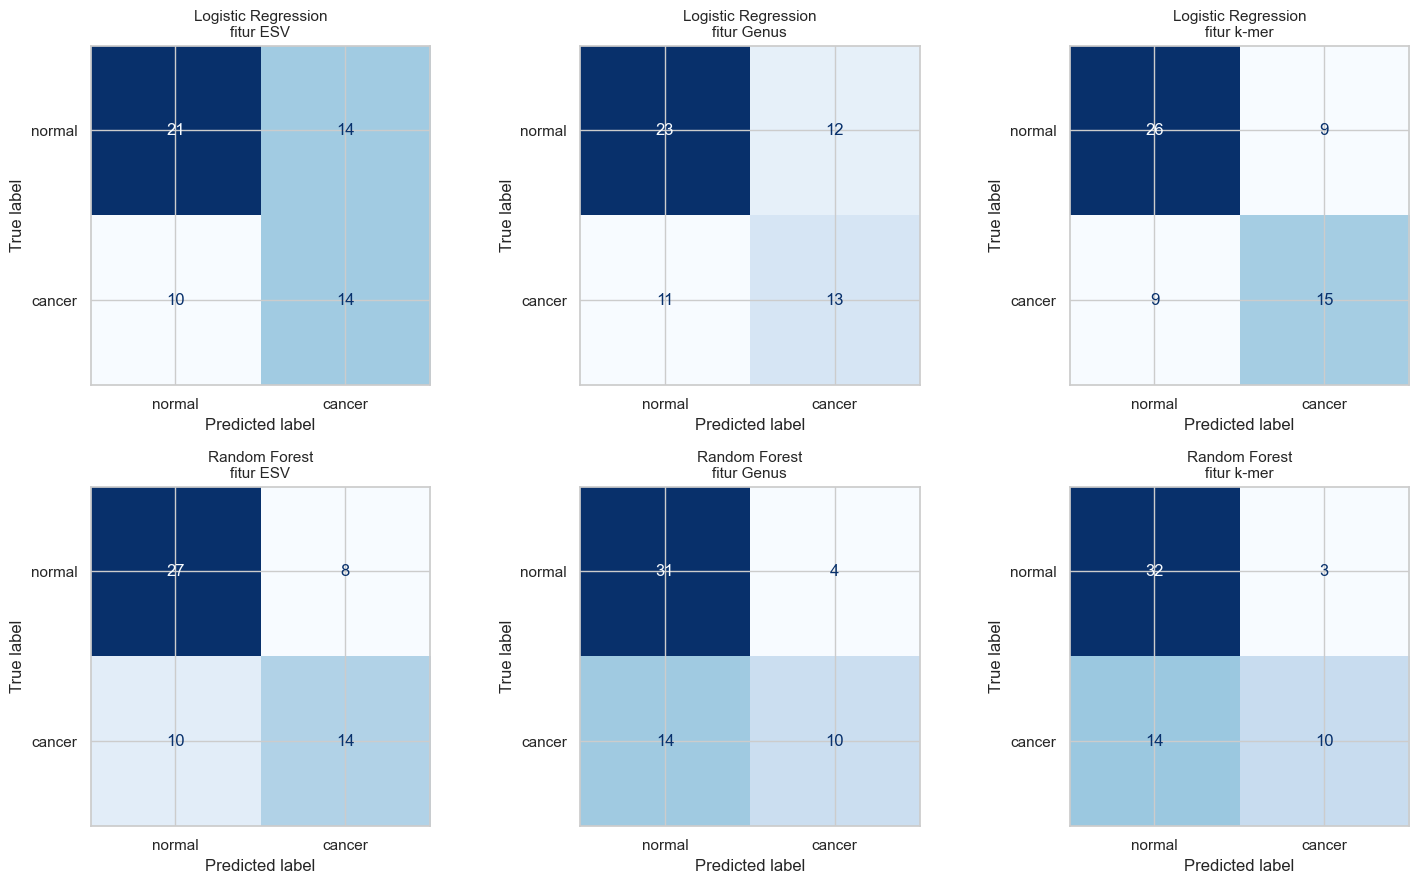

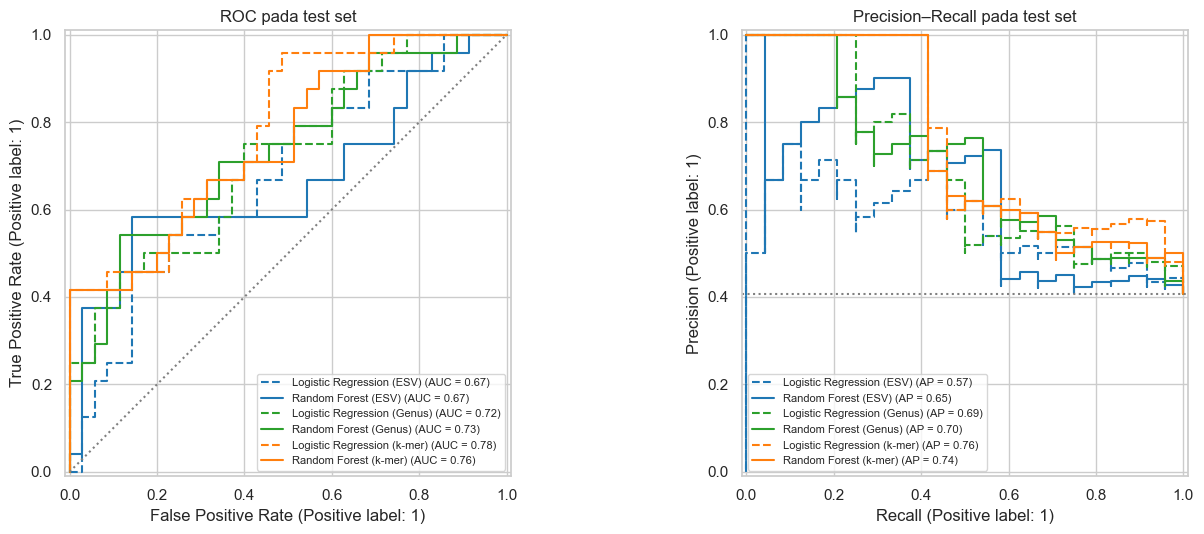

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, feature_name in enumerate(FEATURE_SETS):
    for row, model_name in enumerate(MODEL_NAMES):
        cm = confusion_matrix(y_test, (test_prob[(feature_name, model_name)] >= 0.5).astype(int), labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["normal", "cancer"]).plot(
            ax=axes[row, col], cmap="Blues", colorbar=False)
        axes[row, col].set_title(f"{model_name}\nfitur {feature_name}", fontsize=11)
fig.tight_layout(); fig.savefig(RESULTS / "09_confusion_matrix.png", dpi=180)

LINE_STYLE = {"Logistic Regression": "--", "Random Forest": "-"}
COLOR = {"ESV": "tab:blue", "Genus": "tab:green", "k-mer": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for (feature_name, model_name), prob in test_prob.items():
    label = f"{model_name} ({feature_name})"
    roc = RocCurveDisplay.from_predictions(y_test, prob, name=label, ax=axes[0])
    pr = PrecisionRecallDisplay.from_predictions(y_test, prob, name=label, ax=axes[1])
    for display_obj in (roc, pr):                      # gaya garis diatur setelah plot (kompatibel lintas versi)
        display_obj.line_.set_linestyle(LINE_STYLE[model_name])
        display_obj.line_.set_color(COLOR[feature_name])
axes[0].plot([0, 1], [0, 1], ":", color="grey"); axes[0].set_title("ROC pada test set")
axes[1].axhline(y_test.mean(), ls=":", color="grey"); axes[1].set_title("Precision–Recall pada test set")
for axis in axes:
    axis.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "10_roc_pr.png", dpi=180)
plt.show(); plt.close("all")

## 16. Validasi silang K-Fold (5-fold, nested)
Satu test set 20% (±58 sampel) bisa kebetulan mudah atau sulit. Karena itu performa juga diestimasi
dengan **5-fold stratified cross-validation pada seluruh sampel**; di setiap fold, tuning hyperparameter
dilakukan ulang hanya pada data training fold tersebut (*nested CV*), sehingga tidak ada kebocoran.

In [19]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
cv_rows = []
for feature_name, table in FEATURE_SETS.items():
    for model_name in MODEL_NAMES:
        pipe, grid = make_model(model_name)
        nested = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                              scoring="roc_auc", n_jobs=1)
        scores_cv = cross_validate(nested, table.to_numpy(dtype=float), y, cv=outer_cv,
                                   scoring=["f1", "roc_auc", "accuracy", "balanced_accuracy"])
        cv_rows.append(dict(Fitur=feature_name, Model=model_name,
                            CV_F1_mean=scores_cv["test_f1"].mean(), CV_F1_std=scores_cv["test_f1"].std(),
                            CV_ROC_AUC_mean=scores_cv["test_roc_auc"].mean(),
                            CV_ROC_AUC_std=scores_cv["test_roc_auc"].std(),
                            CV_Accuracy_mean=scores_cv["test_accuracy"].mean(),
                            CV_Balanced_acc_mean=scores_cv["test_balanced_accuracy"].mean()))
        print(f"{feature_name:6s} | {model_name:20s} selesai")
cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(RESULTS / "kfold_nested_cv.csv", index=False)
display(cv_table.round(4))

ESV    | Logistic Regression  selesai


ESV    | Random Forest        selesai


Genus  | Logistic Regression  selesai


Genus  | Random Forest        selesai


k-mer  | Logistic Regression  selesai


k-mer  | Random Forest        selesai


,Fitur,Model,CV_F1_mean,CV_F1_std,CV_ROC_AUC_mean,CV_ROC_AUC_std,CV_Accuracy_mean,CV_Balanced_acc_mean
0,ESV,Logistic Regression,0.5808,0.0365,0.7138,0.0192,0.6336,0.6312
1,ESV,Random Forest,0.4922,0.0217,0.6798,0.0314,0.6338,0.6039
2,Genus,Logistic Regression,0.6086,0.1119,0.7450,0.0737,0.6916,0.6780
3,Genus,Random Forest,0.5728,0.1069,0.7650,0.0900,0.7293,0.6884
4,k-mer,Logistic Regression,0.6140,0.0503,0.7513,0.0495,0.7018,0.6827
5,k-mer,Random Forest,0.5544,0.1238,0.7698,0.0651,0.7222,0.6786


### 16b. Analisis sensitivitas: apakah model menangkap efek teknis atau usia?
Performa tinggi belum tentu berasal dari biologi. Tiga pemeriksaan:
1. **Model kontrol teknis:** prediksi label hanya dari metrik QC read (kualitas, GC, % lolos filter).
   AUC mendekati 0,5 berarti kualitas sekuensing tidak membedakan kelompok.
2. **Tag instrumen di metadata ENA:** sebagian sampel cancer bertag "Illumina MiSeq", sedangkan seluruh
   sampel normal bertag "454 GS". Bila tag ini mencerminkan batch teknis, model dapat "belajar" batch.
   Model diuji ulang tanpa sampel bertag tersebut, dan diuji apakah k-mer dapat menebak tag di antara
   sampel cancer.
3. **Usia:** usia adalah faktor risiko kanker kolorektal sekaligus memengaruhi mikrobioma (*confounder*).

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score


def nested_auc(table, target, rows_mask=None):
    """Rerata ROC-AUC nested 5-fold untuk LR dan RF pada subset baris tertentu."""
    rows_mask = np.ones(len(target), bool) if rows_mask is None else rows_mask
    values = table.to_numpy(dtype=float)[rows_mask]
    result = {}
    for model_name in MODEL_NAMES:
        pipe, grid = make_model(model_name)
        nested = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                              scoring="roc_auc", n_jobs=1)
        result[model_name] = cross_val_score(nested, values, target[rows_mask], cv=outer_cv,
                                             scoring="roc_auc").mean()
    return result


qc_metrics = qc.loc[samples, ["R1_mean_q", "R1_pct_q30", "R1_gc_pct", "R1_pct_start_TAC", "pct_pass_filter"]]
qc_auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")),
                         qc_metrics, y, cv=outer_cv, scoring="roc_auc")
print(f"1) Model kontrol teknis (metrik QC saja): ROC-AUC {qc_auc.mean():.3f} ± {qc_auc.std():.3f}")

instrument_tag = cohort.loc[samples, "instrument_model"]
display(pd.crosstab(instrument_tag.rename("tag instrumen ENA"), labels.rename("label")))
untagged = instrument_tag.ne("Illumina MiSeq").to_numpy()
cancer_only = labels.eq("cancer").to_numpy()
tag_target = instrument_tag.eq("Illumina MiSeq").astype(int).to_numpy()
sensitivity_rows = []
for feature_name, table in FEATURE_SETS.items():
    full = cv_table.set_index(["Fitur", "Model"]).CV_ROC_AUC_mean
    without_tag = nested_auc(table, y, untagged)
    tag_prediction = nested_auc(table, tag_target, cancer_only)
    for model_name in MODEL_NAMES:
        sensitivity_rows.append(dict(Fitur=feature_name, Model=model_name,
                                     AUC_semua_sampel=full[(feature_name, model_name)],
                                     AUC_tanpa_sampel_bertag=without_tag[model_name],
                                     AUC_menebak_tag_di_cancer=tag_prediction[model_name]))
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(RESULTS / "sensitivitas_batch.csv", index=False)
print("2) Sensitivitas tag instrumen (nested 5-fold ROC-AUC):")
display(sensitivity.round(3))

age = pd.to_numeric(cohort.loc[samples, "Age"], errors="coerce")
print(f"3) Usia median: cancer {age[cancer_only].median():.0f} th, normal {age[~cancer_only].median():.0f} th; "
      f"ROC-AUC usia saja: {roc_auc_score(y[age.notna().to_numpy()], age.dropna()):.3f}")

1) Model kontrol teknis (metrik QC saja): ROC-AUC 0.622 ± 0.053


label,cancer,normal
tag instrumen ENA,,
454 GS,94,172
Illumina MiSeq,26,0


2) Sensitivitas tag instrumen (nested 5-fold ROC-AUC):


,Fitur,Model,AUC_semua_sampel,AUC_tanpa_sampel_bertag,AUC_menebak_tag_di_cancer
0,ESV,Logistic Regression,0.714,0.691,0.520
1,ESV,Random Forest,0.680,0.702,0.493
2,Genus,Logistic Regression,0.745,0.761,0.446
3,Genus,Random Forest,0.765,0.760,0.567
4,k-mer,Logistic Regression,0.751,0.738,0.555
5,k-mer,Random Forest,0.770,0.758,0.385


3) Usia median: cancer 64 th, normal 54 th; ROC-AUC usia saja: 0.715


## 17. Fitur yang berkontribusi pada model
**RF_importance:** *impurity importance* Random Forest. **LR_coefficient:** koefisien Logistic Regression
pada fitur CLR terstandarisasi (positif = condong ke cancer, negatif = condong ke normal). Tabel utama
memakai model **fitur Genus** (dilatih pada data training) karena paling mudah ditafsirkan; ESV dan k-mer
teratas ditampilkan sebagai pelengkap. Kontribusi model bukan bukti kausal; fitur berkorelasi dapat
saling menggantikan.

,RF_importance,LR_coefficient,mean_pct_cancer,mean_pct_normal,FDR_BH
Genus,,,,,
Porphyromonas,0.0436,0.1567,0.5828,0.0015,0.0000
Peptostreptococcus,0.0339,0.1373,0.0434,0.0003,0.0000
Parvimonas,0.0207,0.1103,0.0403,0.0008,0.0000
Fusobacterium,0.0204,0.1091,0.3324,0.0099,0.0001
Evtepia,0.0179,0.0861,0.0794,0.0518,0.0120
Merdibacter,0.0168,-0.0991,0.0016,0.0047,0.1842
Agathobaculum/Butyricicoccus,0.0138,-0.1007,0.0854,0.1398,0.0364
Gemmiger,0.0131,-0.1210,0.5362,0.8057,0.1145
Collinsella,0.0129,0.0843,1.7054,1.1126,0.1104


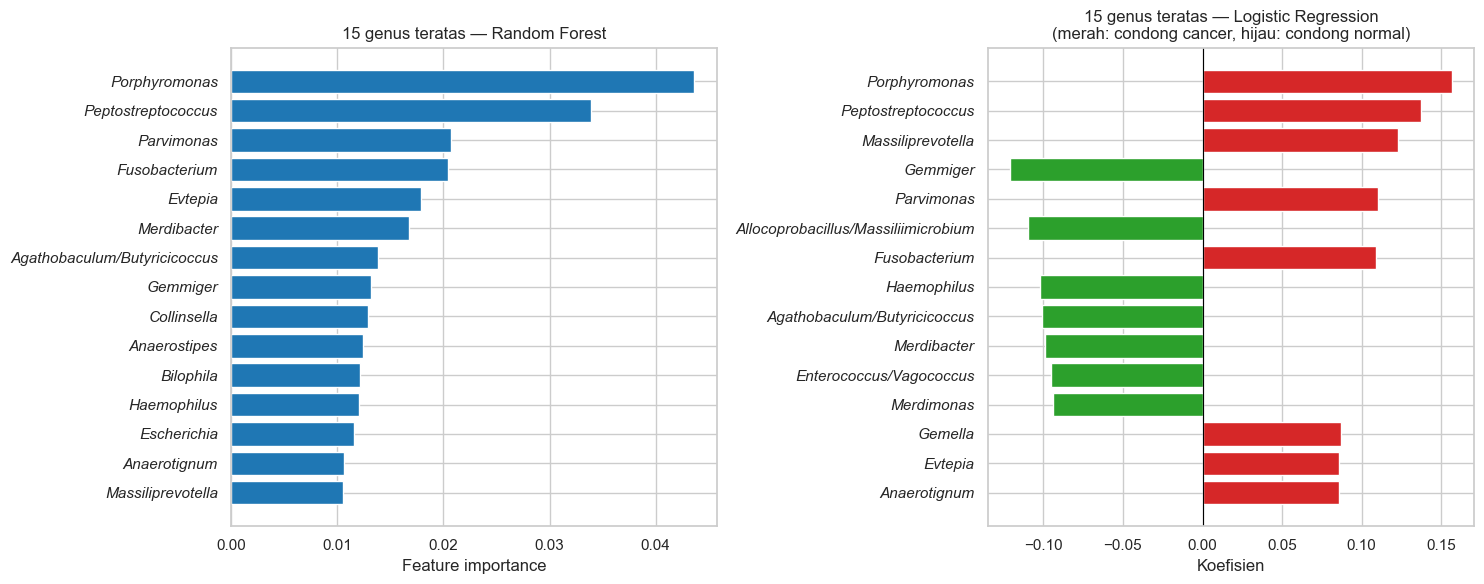

10 ESV teratas (RF):


,RF_importance,LR_coefficient,genus,nearest_reference,identity_pct
ESV,,,,,
ESV0076,0.0199,0.0268,Porphyromonas,Porphyromonas asaccharolytica,100.0
ESV0769,0.0079,-0.0151,Anaerostipes,Anaerostipes hadrus,99.5
ESV0410,0.0064,0.0203,Parvimonas,Parvimonas micra,100.0
ESV1713,0.0056,0.0070,Blautia,Blautia provencensis,99.5
ESV0390,0.0050,-0.0126,Gemmiger,Gemmiger formicilis,99.5
ESV0012,0.0048,0.0109,Collinsella,Collinsella aerofaciens,100.0
ESV0669,0.0047,0.0207,Peptostreptococcus,Peptostreptococcus stomatis,100.0
ESV0780,0.0046,0.0096,Collinsella,Collinsella aerofaciens,99.5
ESV0698,0.0044,-0.0004,unclassified,Diplocloster agilis,94.0


10 k-mer teratas (RF): {'ACTCTC': 0.0095, 'GCCCAA': 0.0083, 'CTTGCC': 0.0072, 'GAAAAG': 0.0066, 'CCCAAC': 0.0061, 'TCTCTA': 0.0058, 'TAGCTC': 0.0049, 'GTACGT': 0.0048, 'TGCCTT': 0.0045, 'AGAAGT': 0.0042}


In [21]:
def contribution_table(feature_name):
    """Gabungkan importance RF dan koefisien LR dari model training untuk satu representasi."""
    columns = FEATURE_SETS[feature_name].columns.to_numpy()
    rf_pipe, lr_pipe = fitted[(feature_name, "Random Forest")], fitted[(feature_name, "Logistic Regression")]
    return pd.DataFrame({
        "RF_importance": pd.Series(rf_pipe["model"].feature_importances_, columns[rf_pipe["prevalence"].support_]),
        "LR_coefficient": pd.Series(lr_pipe["model"].coef_[0], columns[lr_pipe["prevalence"].support_]),
    }).sort_values("RF_importance", ascending=False)


contrib = contribution_table("Genus").join(diff[["mean_pct_cancer", "mean_pct_normal", "FDR_BH"]])
contrib.index.name = "Genus"
contrib.to_csv(RESULTS / "kontribusi_fitur_genus.csv")
display(contrib.head(15).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_rf = contrib.head(15).iloc[::-1]
axes[0].barh(top_rf.index, top_rf.RF_importance, color="tab:blue")
axes[0].set(title="15 genus teratas — Random Forest", xlabel="Feature importance")
top_lr = contrib.reindex(contrib.LR_coefficient.abs().sort_values(ascending=False).index).head(15).iloc[::-1]
axes[1].barh(top_lr.index, top_lr.LR_coefficient,
             color=np.where(top_lr.LR_coefficient > 0, "tab:red", "tab:green"))
axes[1].axvline(0, color="black", lw=.8)
axes[1].set(title="15 genus teratas — Logistic Regression\n(merah: condong cancer, hijau: condong normal)",
            xlabel="Koefisien")
for axis in axes:
    for tick in axis.get_yticklabels():
        tick.set_style("italic")
fig.tight_layout(); fig.savefig(RESULTS / "11_kontribusi_fitur.png", dpi=180)
plt.show(); plt.close("all")

contrib_esv = contribution_table("ESV").join(taxonomy[["genus", "nearest_reference", "identity_pct"]])
contrib_esv.index.name = "ESV"
contrib_esv.to_csv(RESULTS / "kontribusi_fitur_esv.csv")
print("10 ESV teratas (RF):")
display(contrib_esv.head(10).round(4))
contrib_kmer = contribution_table("k-mer")
contrib_kmer.to_csv(RESULTS / "kontribusi_fitur_kmer.csv")
print("10 k-mer teratas (RF):", contrib_kmer.RF_importance.head(10).round(4).to_dict())

## 18. Simpan model dan ekspor hasil
Model yang disimpan adalah pipeline hasil tuning pada data training (dievaluasi di test set di atas).
Untuk memuat ulang, jalankan dulu sel definisi kelas `PrevalenceFilter` dan `CLRTransform` (bagian 14).
Jangan memuat berkas joblib dari sumber tak tepercaya. ZIP hasil tidak menyertakan FASTQ (sudah ada
di `data/`).

In [22]:
import joblib
for (feature_name, model_name), pipeline in fitted.items():
    filename = f"{model_name.lower().replace(' ', '_')}_{feature_name.lower().replace('-', '')}.joblib"
    joblib.dump(pipeline, MODELS / filename)
write_json(MODELS / "skema_fitur.json", {
    "ESV_order": list(esv.columns), "ESV_sequences_fasta": "results/esv_sequences.fasta",
    "Genus_order": list(genus_counts.columns), "kmer_order": list(kmer.columns), "positive_class": "cancer",
    "input": f"hitungan ESV/k-mer dari {RAREFY_DEPTH} read R1 rarefied (200 bp, maxEE 2)"})
manifest = {
    "dataset": STUDY, "data_format": "FASTQ (R1+R2 utuh, gzip), MD5 ENA terverifikasi",
    "n_fastq_files": len(jobs), "fastq_total_gb": round(sum(j[2] for j in jobs) / 1e9, 2),
    "samples_cohort": len(cohort), "samples_analyzed": len(samples),
    "class_counts": labels.value_counts().to_dict(),
    "parameters": dict(TRUNC_LEN=TRUNC_LEN, MAX_EE=MAX_EE, RAREFY_DEPTH=RAREFY_DEPTH, KMER_K=KMER_K,
                       MIN_PREVALENCE=MIN_PREVALENCE, SEED=SEED),
    "reference": {"url": REF_URL, "sha256": ref_sha256, "v4_references": len(v4_seq)},
    "validation": "stratified 80/20 hold-out + nested 5-fold CV", "library_versions": LIBRARIES,
    "completed_utc": datetime.now(timezone.utc).isoformat(),
}
write_json(RESULTS / "manifest_analisis.json", manifest)
zip_path = Path(shutil.make_archive(str(PROJECT_DIR / "hasil_proyek2"), "zip", OUT))
print("Model dan hasil tersimpan di:", OUT)
print("ZIP:", zip_path.name, f"({zip_path.stat().st_size / 1e6:.1f} MB)")

Model dan hasil tersimpan di: D:\Quick Access\Documents\ChatGPT\projek bioinformatika 2\proyek2_Kanker_Kolorektal_16S_FASTQ\hasil_proyek2
ZIP: hasil_proyek2.zip (6.1 MB)


## 19. Ringkasan hasil aktual
Ringkasan berikut dihasilkan otomatis setelah semua tahap selesai.

In [23]:
best_cv = cv_table.sort_values("CV_ROC_AUC_mean", ascending=False).iloc[0]
summary = {
    "sampel_dianalisis": len(samples), "kelas": labels.value_counts().to_dict(),
    "read_R1_total": int(qc.R1_n_reads.sum()), "rerata_pct_lolos_filter": round(qc.pct_pass_filter.mean(), 2),
    "ESV_setelah_filter_global": esv.shape[1], "genus_terklasifikasi": genus_counts.shape[1],
    "MannWhitney_genus": {"diuji": len(diff), "FDR005": int(diff.significant.sum()),
                          "signifikan": diff.index[diff.significant].tolist()},
    "MannWhitney_ESV": {"diuji": len(diff_esv), "FDR005": int(diff_esv.significant.sum())},
    "PCA_PC1_PC2": [round(float(evr[0]), 4), round(float(evr[1]), 4)],
    "KMeans_k2_ARI": round(float(ari), 4),
    "test_set": comparison.drop(columns="Parameter").set_index(["Fitur", "Model"]).round(4)
                .reset_index().to_dict("records"),
    "kfold_terbaik": {k: round(v, 4) if isinstance(v, float) else v for k, v in best_cv.items()},
    "genus_teratas_RF": contrib.head(10).index.tolist(),
    "validasi_silang_penulis": validation,
    "kontrol_teknis_QC_AUC": round(float(qc_auc.mean()), 4),
    "sensitivitas_batch": sensitivity.round(4).to_dict("records"),
}
write_json(RESULTS / "ringkasan_hasil.json", summary)
print(json.dumps(summary, indent=2, ensure_ascii=False, default=str))

{
  "sampel_dianalisis": 292,
  "kelas": {
    "normal": 172,
    "cancer": 120
  },
  "read_R1_total": 16113186,
  "rerata_pct_lolos_filter": 96.69,
  "ESV_setelah_filter_global": 12192,
  "genus_terklasifikasi": 280,
  "MannWhitney_genus": {
    "diuji": 169,
    "FDR005": 10,
    "signifikan": [
      "Peptostreptococcus",
      "Porphyromonas",
      "Parvimonas",
      "Fusobacterium",
      "Haemophilus",
      "Evtepia",
      "Gemella",
      "Massiliprevotella",
      "Klebsiella",
      "Agathobaculum/Butyricicoccus"
    ]
  },
  "MannWhitney_ESV": {
    "diuji": 1878,
    "FDR005": 76
  },
  "PCA_PC1_PC2": [
    0.0614,
    0.058
  ],
  "KMeans_k2_ARI": -0.0183,
  "test_set": [
    {
      "Fitur": "ESV",
      "Model": "Logistic Regression",
      "Accuracy": 0.5932,
      "Precision_cancer": 0.5,
      "Recall_cancer": 0.5833,
      "F1_cancer": 0.5385,
      "Specificity": 0.6,
      "Balanced_accuracy": 0.5917,
      "ROC_AUC": 0.6738,
      "PR_AUC": 0.5739
    },
    {

## Catatan interpretasi hasil

Angka di bawah berasal dari eksekusi penuh notebook ini pada 584 berkas FASTQ utuh (5 November 2026,
seed 42); jalankan ulang untuk memverifikasi.

**1. Data dan QC.** 292 orang (120 cancer, 172 normal), 16,1 juta read R1. Kualitas R1 baik
(±89% basa ≥ Q30); R2 menurun di ujung read (±80% ≥ Q30), sehingga analisis memakai R1 200 bp.
±96,7% read lolos filter; tidak ada sampel yang dikeluarkan pada kedalaman 10.000 read.

**2. Validasi pemrosesan.** Profil hasil notebook berkorelasi kuat dengan tabel OTU olahan penulis
(Shannon ρ = 0,81; median korelasi taksa dominan 0,88), sehingga fitur yang dihitung dari FASTQ
mewakili sampel yang benar.

**3. Eksplorasi.** PCA (PC1 6,1%, PC2 5,8%) dan K-Means (ARI −0,02) tidak memisahkan kelompok:
variasi terbesar mikrobioma bukan status kanker. Keragaman pasien kanker sedikit lebih rendah
(Shannon 4,40 vs 4,61).

**4. Uji Mann–Whitney + FDR.** 10 dari 169 genus berbeda bermakna. Lebih tinggi pada cancer:
*Peptostreptococcus*, *Porphyromonas*, *Parvimonas*, *Fusobacterium* (FDR < 0,0001), juga *Evtepia*,
*Gemella*, *Massiliprevotella*, *Klebsiella*; lebih tinggi pada normal: *Haemophilus*,
*Agathobaculum/Butyricicoccus*. Prevalensi *Peptostreptococcus* 31,7% pada cancer vs 2,3% pada normal.

**5. Model (nested 5-fold CV, ROC-AUC):**

| Fitur | Logistic Regression | Random Forest |
|---|---|---|
| ESV | 0,714 | 0,680 |
| Genus | 0,745 | **0,765** |
| k-mer | 0,751 | **0,770** |

Semua jauh di atas baseline (0,50); genus dan k-mer lebih baik dari ESV (ESV terlalu jarang: 93% nol).
Selisih LR vs RF lebih kecil dari variasi antar-fold sehingga **tidak ada model yang terbukti unggul**.
Pada test set (59 sampel) ROC-AUC 0,67–0,78; recall kanker pada ambang 0,5 masih 0,42–0,63.

**6. Kontribusi fitur.** Empat genus teratas pada Random Forest dan koefisien positif terbesar Logistic
Regression adalah *Porphyromonas*, *Peptostreptococcus*, *Parvimonas*, *Fusobacterium* — sama dengan
hasil uji statistik dan konsisten dengan literatur kanker kolorektal (Baxter et al., 2016; Zeller et al.,
2014; Kostic et al., 2012).

**7. Sensitivitas.** Tag instrumen di metadata ENA bukan sumber performa (AUC hampir sama tanpa sampel
bertag; fitur tidak dapat menebak tag). Metrik QC saja memberi AUC 0,62, dan **usia** (median 64 vs 54
tahun) memberi AUC 0,715 — usia adalah *confounder* penting yang belum dikoreksi.

**Keterbatasan:** satu kohor, tanpa validasi eksternal; usia belum dikoreksi; pipeline tanpa denoising
dan penghapusan chimera; V4 hanya andal sampai genus. Hasil bukan alat diagnosis klinis.

## Bahan proposal, laporan, dan presentasi
**Proposal 2–3 halaman:** latar belakang (kanker kolorektal, peran mikrobioma usus, kebutuhan deteksi
non-invasif) → tujuan → dataset PRJNA290926 (FASTQ 16S V4) → metode (QC FASTQ, ESV/k-mer, PCA/K-Means,
Mann–Whitney + FDR, LR vs RF, evaluasi) → luaran.

**Laporan akhir 8–12 halaman:** judul, abstrak, pendahuluan, metodologi, hasil dan pembahasan, kesimpulan,
referensi. Gunakan berkas di `hasil_proyek2/results/` (tabel CSV dan grafik bernomor 01–10).

**Presentasi 10–15 menit:** masalah (2 menit), data FASTQ dan QC (3), eksplorasi PCA/K-Means/uji
statistik (3), dua model dan evaluasi (4), kesimpulan dan keterbatasan (2).

**Pertanyaan yang perlu dikuasai:** isi 4 baris FASTQ dan skor Phred; alasan memotong 200 bp dan maxEE;
alasan rarefaction; ESV vs k-mer; mengapa CLR; mengapa Mann–Whitney (bukan uji berpasangan); mengapa
recall/ROC-AUC lebih penting dari accuracy pada data tidak seimbang; batas interpretasi genus dari V4.

**Jadwal:** proposal 6 Nov; diskusi kemajuan 13/20/27 Nov; diskusi artikel 1 Des; presentasi 4 Des;
perbaikan artikel 11 Des 2026.

## Referensi
- Baxter NT, Ruffin MT, Rogers MAM, Schloss PD (2016). *Microbiota-based model improves the sensitivity of
  fecal immunochemical test for detecting colonic lesions.* Genome Medicine 8:37.
  [doi:10.1186/s13073-016-0290-3](https://doi.org/10.1186/s13073-016-0290-3). Sumber dataset.
- Kozich JJ et al. (2013). *Development of a dual-index sequencing strategy and curation pipeline for
  analyzing amplicon sequence data on the MiSeq Illumina sequencing platform.* Applied and Environmental
  Microbiology 79(17):5112–5120. [doi:10.1128/AEM.01043-13](https://doi.org/10.1128/AEM.01043-13).
- Edgar RC, Flyvbjerg H (2015). *Error filtering, pair assembly and error correction for next-generation
  sequencing reads.* Bioinformatics 31(21):3476–3482.
  [doi:10.1093/bioinformatics/btv401](https://doi.org/10.1093/bioinformatics/btv401). Dasar filter expected errors.
- Callahan BJ, McMurdie PJ, Holmes SP (2017). *Exact sequence variants should replace operational taxonomic
  units in marker-gene data analysis.* The ISME Journal 11:2639–2643.
  [doi:10.1038/ismej.2017.119](https://doi.org/10.1038/ismej.2017.119).
- Gloor GB et al. (2017). *Microbiome datasets are compositional: and this is not optional.* Frontiers in
  Microbiology 8:2224. [doi:10.3389/fmicb.2017.02224](https://doi.org/10.3389/fmicb.2017.02224). Dasar CLR.
- Zeller G et al. (2014). *Potential of fecal microbiota for early-stage detection of colorectal cancer.*
  Molecular Systems Biology 10:766. [doi:10.15252/msb.20145645](https://doi.org/10.15252/msb.20145645).
- Kostic AD et al. (2012). *Genomic analysis identifies association of Fusobacterium with colorectal
  carcinoma.* Genome Research 22:292–298. [doi:10.1101/gr.126573.111](https://doi.org/10.1101/gr.126573.111).
- Castellarin M et al. (2012). *Fusobacterium nucleatum infection is prevalent in human colorectal
  carcinoma.* Genome Research 22:299–306. [doi:10.1101/gr.126516.111](https://doi.org/10.1101/gr.126516.111).
- [NCBI RefSeq Targeted Loci 16S](https://ftp.ncbi.nlm.nih.gov/refseq/TargetedLoci/Bacteria/) dan
  [ENA Portal API](https://www.ebi.ac.uk/ena/portal/api/).